# Build, Inspect, and Optimize a CNN on CIFAR-10


## Part 0 — Runtime and imports

In Colab, select **Runtime → Change runtime type → T4 GPU** (if available). A GPU is recommended .

A single Colab session is generally sufficient for modest CNN experiments on CIFAR-10. Runtime availability and duration are not guaranteed, so save important checkpoints and experiment results to persistent storage if needed.

In [1]:
# Check the runtime device
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [2]:
# Reproducibility: this makes runs more comparable, though GPU operations
# are not guaranteed to be perfectly deterministic in every environment.
import os
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [ ]:

import importlib, subprocess, sys, time, json, copy
for _pkg, _pip in [("sklearn", "scikit-learn"), ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("torchvision", "torchvision")]:
    try:
        importlib.import_module(_pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pip])

import pandas as pd
import sklearn
import torchvision
print("torchvision:", torchvision.__version__, "| scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__)

for _d in ["results", "checkpoints", "figures"]:
    os.makedirs(_d, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

EPOCHS = 20 if torch.cuda.is_available() else 8
USE_CACHE = True
print("Epoch budget per run:", EPOCHS)


torchvision: 0.29.1+cu130 | scikit-learn: 1.6.1 | pandas: 2.2.3
Epoch budget per run: 20


## Part 1 — Load and understand CIFAR-10

CIFAR-10 contains 60,000 colour images of size **32 × 32 × 3**, divided into 10 classes. There are 50,000 training images and 10,000 official test images. We will take a validation subset from the training data so that the test set remains untouched until the final evaluation.<br>
## important Note
brefore continuing be sure to calculate train mean and std **seperately from the test split** and normalize the images with them. transforms are left blank in the cell below so that you would compose them yourself, please at the very least construct the normalization transform.

The normalization was computed based on 45000 images belonging to the training split. Consequently, since no use of the 5000 validation and test set images was made at this stage, any form of data leakage was successfully prevented.

In [ ]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
_raw = datasets.CIFAR10(root="./data", train=True, download=True)           
_perm = torch.randperm(len(_raw), generator=torch.Generator().manual_seed(SEED)).tolist()
_train_raw = _raw.data[_perm[5000:]]                                         # (45000, 32, 32, 3) uint8
MEAN = tuple(float((_train_raw[..., c] / 255.0).mean()) for c in range(3))
STD = tuple(float((_train_raw[..., c] / 255.0).std()) for c in range(3))
del _raw, _perm, _train_raw
print("Train-split MEAN:", [round(m, 4) for m in MEAN], "| STD:", [round(s, 4) for s in STD])

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Download the training set twice so train and validation can use different transforms.
train_augmented = datasets.CIFAR10(root="./data", train=True, download=True,
                                   transform=train_transform)
train_for_val = datasets.CIFAR10(root="./data", train=True, download=True,
                                 transform=eval_transform)
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True,
                                transform=eval_transform)

# Fixed, reproducible 90/10 split of the 50,000 training examples.
generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_augmented), generator=generator).tolist()
val_size = 5000
val_indices = indices[:val_size]
train_indices = indices[val_size:]

train_dataset = Subset(train_augmented, train_indices)
val_dataset = Subset(train_for_val, val_indices)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=2, pin_memory=torch.cuda.is_available())

print(f"Train: {len(train_dataset):,}")
print(f"Validation: {len(val_dataset):,}")
print(f"Test: {len(test_dataset):,}")

100%|██████████| 170M/170M [27:10<00:00, 105kB/s]


Train-split MEAN: [0.4913, 0.4822, 0.4466] | STD: [0.247, 0.2436, 0.2617]
Train: 45,000
Validation: 5,000
Test: 10,000


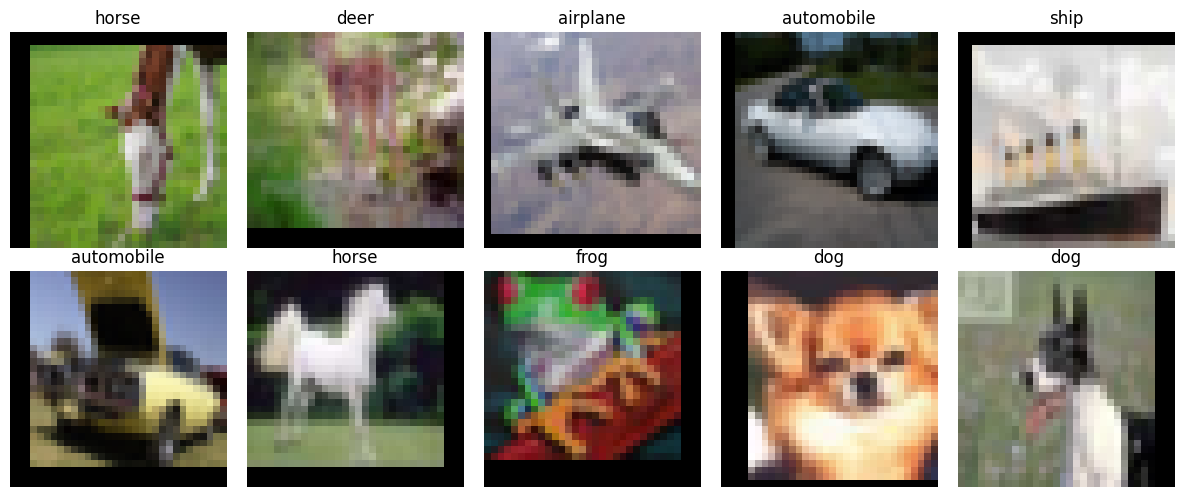

In [5]:
# Visualize a batch. Undo normalization for display.
def denormalize(images):
    mean = torch.tensor(MEAN).view(1, 3, 1, 1)
    std = torch.tensor(STD).view(1, 3, 1, 1)
    return (images.cpu() * std + mean).clamp(0, 1)

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, image, label in zip(axes.flat, images[:10], labels[:10]):
    ax.imshow(denormalize(image.unsqueeze(0))[0].permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

First, a series of sanity checks was conducted to ensure the correctness of the data preparation pipeline. These checks comprise four main axes:
First, verifying the shape of the model’s input tensors;
second, checking the size of each data split and confirming the complete disjointness among the training, validation, and test sets, ensuring that no sample simultaneously appears in more than one set;
third, evaluating the class balance to ensure a relatively uniform distribution of labels; and
fourth, assessing the normalization statistics. It is worth noting that these statistics were computed on the normalized images based on the evaluation transform that is, without applying any data augmentation so that the mean and standard deviation accurately reflect the true and untouched distribution of the data

In [ ]:
x0, y0 = train_dataset[0]
print("One training sample -> tensor type:", type(x0).__name__, "| shape:", tuple(x0.shape), "| dtype:", x0.dtype, "| label:", y0, f"({CLASS_NAMES[y0]})")
raw_arr = datasets.CIFAR10(root="./data", train=True, download=False).data
print("Raw stored image array (NumPy / PIL layout) shape for one image:", raw_arr[0].shape, "(H, W, C)")

assert set(train_indices).isdisjoint(val_indices), "train/val overlap!"
print("\nTrain/val indices are disjoint:", set(train_indices).isdisjoint(val_indices))

def class_counts(ds_labels):
    return np.bincount(ds_labels, minlength=10)
all_train_targets = np.array(train_augmented.targets)
count_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": class_counts(all_train_targets[train_indices]),
    "val": class_counts(all_train_targets[val_indices]),
    "test": class_counts(np.array(test_dataset.targets)),
})
print(count_df.to_string(index=False))

def channel_stats(ds):
    loader = DataLoader(ds, batch_size=500, shuffle=False, num_workers=0)
    n, s, s2 = 0, torch.zeros(3, dtype=torch.float64), torch.zeros(3, dtype=torch.float64)
    for xb, _ in loader:
        xb = xb.double()
        n += xb.shape[0] * xb.shape[2] * xb.shape[3]
        s += xb.sum(dim=(0, 2, 3)); s2 += (xb ** 2).sum(dim=(0, 2, 3))
    mean = s / n
    return mean.numpy().round(4), (s2 / n - mean ** 2).sqrt().numpy().round(4)

print("\nMEAN used (train split only):", np.round(MEAN, 4), "| STD used (train split only):", np.round(STD, 4))
for name, ds in [("train split", Subset(train_for_val, train_indices)), ("validation split", val_dataset), ("test split", test_dataset)]:
    m, s = channel_stats(ds)
    print(f"Normalized {name:17s} -> per-channel mean {m} | std {s}")


One training sample -> tensor type: Tensor | shape: (3, 32, 32) | dtype: torch.float32 | label: 4 (deer)
Raw stored image array (NumPy / PIL layout) shape for one image: (32, 32, 3) (H, W, C)

Train/val indices are disjoint: True
     class  train  val  test
  airplane   4470  530  1000
automobile   4517  483  1000
      bird   4522  478  1000
       cat   4522  478  1000
      deer   4507  493  1000
       dog   4503  497  1000
      frog   4483  517  1000
     horse   4482  518  1000
      ship   4489  511  1000
     truck   4505  495  1000

MEAN used (train split only): [0.4913 0.4822 0.4466] | STD used (train split only): [0.247  0.2436 0.2617]
Normalized train split       -> per-channel mean [-0.  0.  0.] | std [1. 1. 1.]
Normalized validation split  -> per-channel mean [ 0.002  -0.0001 -0.0025] | std [0.9993 0.9972 0.9963]
Normalized test split        -> per-channel mean [0.0116 0.0122 0.0146] | std [0.9984 0.9973 0.9996]


## Part 2 — Design and train your first CNN

Build a baseline CNN. Your model should accept an image batch with shape `(batch, 3, 32, 32)` and return **10 class logits** per image. Do not apply softmax in the model when using `CrossEntropyLoss`; that loss expects raw logits.

You may start with two or three convolutional blocks. A typical block is:

`Convolution → Batch Normalization (optional) → ReLU → Pooling (optional)`

The exact architecture is yours to design. Keep the baseline simple enough that you can explain every layer.

In [7]:
import torch.nn as nn
import torch.nn.functional as F

class BaselineCNN(nn.Module):
    """Baseline: 3 x [Conv3x3 -> BatchNorm -> ReLU -> MaxPool2] -> GlobalAvgPool -> FC(128) -> ReLU -> Dropout -> FC(10).
    `use_pool=False` removes the three max-pool layers (only used to answer a question about downsampling)."""
    def __init__(self, num_classes=10, use_pool=True):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, kernel_size=3, stride=1, padding=1, bias=False),
                      nn.BatchNorm2d(cout), nn.ReLU()]
            if use_pool:
                layers.append(nn.MaxPool2d(2))
            return layers
        self.features = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128), nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, num_classes))

    def forward(self, x):          # returns raw logits (no softmax: CrossEntropyLoss applies log-softmax itself)
        return self.classifier(self.features(x))

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# The same architecture written as a configuration (it is re-used in Part 4/5 as "run 01").
BASELINE_ARCH = {
    "input_channels": 3, "num_classes": 10, "activation": "relu",
    "conv_blocks": [
        {"out_channels": 32, "kernel_size": 3, "stride": 1, "padding": 1, "batch_norm": True, "pool": 2},
        {"out_channels": 64, "kernel_size": 3, "stride": 1, "padding": 1, "batch_norm": True, "pool": 2},
        {"out_channels": 128, "kernel_size": 3, "stride": 1, "padding": 1, "batch_norm": True, "pool": 2},
    ],
    "classifier_hidden": 128, "dropout": 0.3,
}

baseline = BaselineCNN().to(device)
print(baseline)
print("\nTrainable parameters:", f"{count_params(baseline):,}")

# Layer-by-layer output shapes for a single image (shows how the resolution changes).
x = torch.zeros(1, 3, 32, 32, device=device)
print(f"\n{'input':28s}", tuple(x.shape))
with torch.no_grad():
    baseline.eval()
    for name, layer in baseline.features.named_children():
        x = layer(x)
        print(f"{'features.' + name + ' ' + layer.__class__.__name__:28s}", tuple(x.shape))
    out = baseline.classifier(x)
    print(f"{'classifier output (logits)':28s}", tuple(out.shape))

# Parameters per layer
param_rows = [(n, tuple(p.shape), p.numel()) for n, p in baseline.named_parameters()]
print("\nParameters per tensor:")
print(pd.DataFrame(param_rows, columns=["tensor", "shape", "count"]).to_string(index=False))


BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(

### Training and validation loop

You should record loss and accuracy after every epoch. Training accuracy is calculated on augmented training batches, so it is a useful trend rather than a perfectly comparable evaluation set. Validation metrics are computed without augmentation.

[run01] params=111,274 | adamw lr=0.001 wd=0.0001 | epochs=20
  epoch  1/20 | train loss 1.5947 acc 0.4030 | val loss 1.4994 acc 0.4650 macroF1 0.4623 | 20s  <- best
  epoch  2/20 | train loss 1.2982 acc 0.5257 | val loss 1.3015 acc 0.5414 macroF1 0.5228 | 21s  <- best
  epoch  3/20 | train loss 1.1746 acc 0.5744 | val loss 1.1107 acc 0.5980 macroF1 0.5841 | 19s  <- best
  epoch  4/20 | train loss 1.0974 acc 0.6073 | val loss 1.1475 acc 0.5856 macroF1 0.5811 | 20s
  epoch  5/20 | train loss 1.0318 acc 0.6316 | val loss 0.9525 acc 0.6622 macroF1 0.6573 | 19s  <- best
  epoch  6/20 | train loss 0.9876 acc 0.6459 | val loss 0.9750 acc 0.6492 macroF1 0.6426 | 19s
  epoch  7/20 | train loss 0.9487 acc 0.6644 | val loss 0.9181 acc 0.6740 macroF1 0.6712 | 20s  <- best
  epoch  8/20 | train loss 0.9082 acc 0.6757 | val loss 0.9597 acc 0.6652 macroF1 0.6533 | 19s
  epoch  9/20 | train loss 0.8765 acc 0.6890 | val loss 0.8642 acc 0.6888 macroF1 0.6840 | 21s  <- best
  epoch 10/20 | train loss 0.

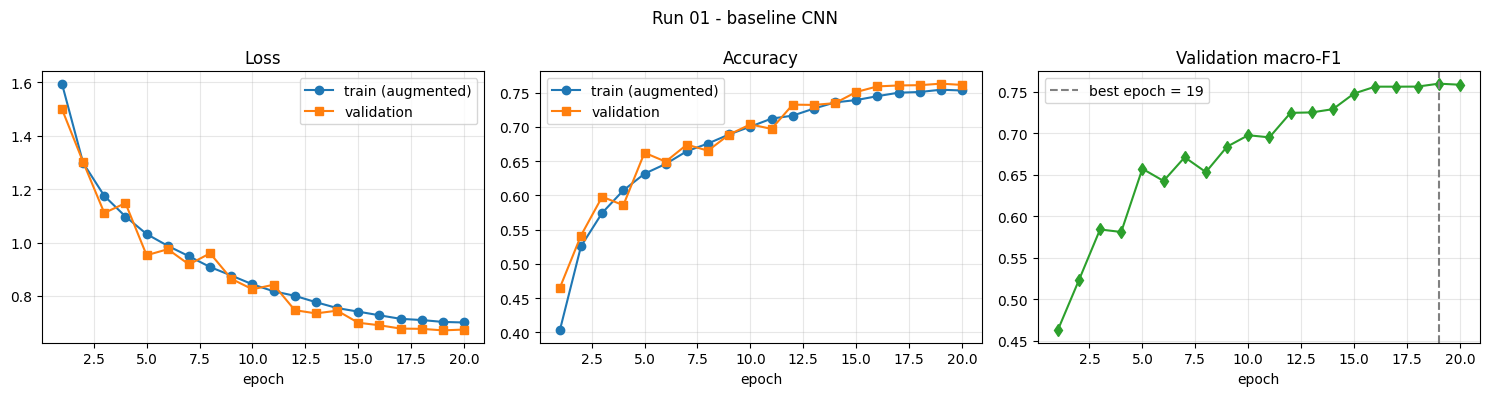

In [ ]:

def confusion_from_preds(y_true, y_pred, num_classes=10):
    return np.bincount(num_classes * np.asarray(y_true) + np.asarray(y_pred), minlength=num_classes ** 2).reshape(num_classes, num_classes)

def metrics_from_confusion(cm):
    """cm[i, j] = number of samples with true class i predicted as class j."""
    cm = cm.astype(np.float64)
    tp = np.diag(cm); support = cm.sum(axis=1); predicted = cm.sum(axis=0)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    w = support / support.sum()
    return {
        "accuracy": tp.sum() / cm.sum(),
        "precision_per_class": precision, "recall_per_class": recall, "f1_per_class": f1, "support": support,
        "macro_precision": precision.mean(), "macro_recall": recall.mean(), "macro_f1": f1.mean(),
        "weighted_precision": (precision * w).sum(), "weighted_recall": (recall * w).sum(), "weighted_f1": (f1 * w).sum(),
    }

@torch.no_grad()
def evaluate(model, loader):
    """Returns loss, accuracy, predictions and targets on a loader (no augmentation, eval mode)."""
    model.eval()
    total_loss, preds, targets = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        logits = model(xb)
        total_loss += F.cross_entropy(logits, yb, reduction="sum").item()
        preds.append(logits.argmax(1).cpu()); targets.append(yb.cpu())
    preds, targets = torch.cat(preds).numpy(), torch.cat(targets).numpy()
    return {"loss": total_loss / len(targets), "acc": float((preds == targets).mean()), "preds": preds, "targets": targets}

def make_optimizer(model, name, lr, weight_decay):
    if name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    if name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=weight_decay)
    raise ValueError(f"unknown optimizer {name}")

def fit(model, run_id, arch, optimizer="adamw", lr=1e-3, weight_decay=1e-4, epochs=None):
    """Train with a cosine learning-rate schedule. After every epoch record train/val loss+accuracy and validation macro-F1.
    The checkpoint of the epoch with the best validation macro-F1 (tie-break: lower validation loss) is kept.
    The test set is never touched here."""
    epochs = epochs or EPOCHS
    signature = {"arch": arch, "optimizer": optimizer, "lr": lr, "weight_decay": weight_decay, "epochs": epochs,
                 "batch_size": BATCH_SIZE, "seed": SEED}
    json_path, ckpt_path = f"results/{run_id}.json", f"checkpoints/{run_id}.pt"
    if USE_CACHE and os.path.exists(json_path) and os.path.exists(ckpt_path):
        cached = json.load(open(json_path))
        if cached["signature"] == json.loads(json.dumps(signature)):
            print(f"[{run_id}] re-using cached result from {json_path}")
            return cached

    criterion = nn.CrossEntropyLoss()
    opt = make_optimizer(model, optimizer, lr, weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    history, best, best_state, t_start = [], None, None, time.time()
    print(f"[{run_id}] params={count_params(model):,} | {optimizer} lr={lr} wd={weight_decay} | epochs={epochs}")
    for epoch in range(1, epochs + 1):
        t0 = time.time(); model.train()
        run_loss, run_correct, seen = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward(); opt.step()
            run_loss += loss.item() * len(yb); run_correct += (logits.argmax(1) == yb).sum().item(); seen += len(yb)
        sched.step()
        val = evaluate(model, val_loader)
        m = metrics_from_confusion(confusion_from_preds(val["targets"], val["preds"]))
        rec = {"epoch": epoch, "train_loss": run_loss / seen, "train_acc": run_correct / seen,
               "val_loss": val["loss"], "val_acc": val["acc"], "val_macro_f1": float(m["macro_f1"]),
               "lr": opt.param_groups[0]["lr"], "seconds": time.time() - t0}
        history.append(rec)
        better = best is None or rec["val_macro_f1"] > best["val_macro_f1"] or \
                 (rec["val_macro_f1"] == best["val_macro_f1"] and rec["val_loss"] < best["val_loss"])
        if better:
            best = rec; best_state = copy.deepcopy(model.state_dict())
        print(f"  epoch {epoch:2d}/{epochs} | train loss {rec['train_loss']:.4f} acc {rec['train_acc']:.4f} | "
              f"val loss {rec['val_loss']:.4f} acc {rec['val_acc']:.4f} macroF1 {rec['val_macro_f1']:.4f} | {rec['seconds']:.0f}s"
              + ("  <- best" if better else ""))
    torch.save(best_state, ckpt_path)
    result = {"run_id": run_id, "signature": json.loads(json.dumps(signature)), "params": count_params(model),
              "history": history, "best_epoch": best["epoch"], "best": best, "train_time_sec": time.time() - t_start,
              "min_val_loss": min(h["val_loss"] for h in history), "max_val_acc": max(h["val_acc"] for h in history)}
    json.dump(result, open(json_path, "w"), indent=1)
    return result

def plot_history(result, title=None, save_as=None):
    h = pd.DataFrame(result["history"])
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].plot(h.epoch, h.train_loss, "o-", label="train (augmented)"); ax[0].plot(h.epoch, h.val_loss, "s-", label="validation")
    ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h.epoch, h.train_acc, "o-", label="train (augmented)"); ax[1].plot(h.epoch, h.val_acc, "s-", label="validation")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
    ax[2].plot(h.epoch, h.val_macro_f1, "d-", color="tab:green"); ax[2].axvline(result["best_epoch"], ls="--", color="gray", label=f"best epoch = {result['best_epoch']}")
    ax[2].set_title("Validation macro-F1"); ax[2].set_xlabel("epoch"); ax[2].legend(); ax[2].grid(alpha=.3)
    fig.suptitle(title or result["run_id"]); plt.tight_layout()
    if save_as: fig.savefig(save_as, dpi=130, bbox_inches="tight")
    plt.show()

# Train the baseline 
set_seed()
baseline = BaselineCNN().to(device)
result01 = fit(baseline, "run01", BASELINE_ARCH, optimizer="adamw", lr=1e-3, weight_decay=1e-4)
plot_history(result01, "Run 01 - baseline CNN", "figures/curves_run01.png")


In [9]:
h = pd.DataFrame(result01["history"])
print("Baseline: best epoch (val macro-F1) =", result01["best_epoch"], "| trainable parameters =", f"{result01['params']:,}")
print(h[["epoch", "train_loss", "val_loss", "train_acc", "val_acc", "val_macro_f1"]].round(4).to_string(index=False))
last = h.iloc[-1]
print(f"\nLast epoch: train loss {last.train_loss:.4f} vs val loss {last.val_loss:.4f} (gap {last.val_loss - last.train_loss:+.4f}); "
      f"train acc {last.train_acc:.4f} vs val acc {last.val_acc:.4f} (gap {last.train_acc - last.val_acc:+.4f})")
print("Epoch with minimum validation loss:", int(h.loc[h.val_loss.idxmin(), "epoch"]))

def profile(model, input_size=(1, 3, 32, 32)):
    stats, hooks = {"macs": 0, "act_elems": 0}, []
    def conv_hook(m, i, o):
        stats["macs"] += o.shape[1] * o.shape[2] * o.shape[3] * m.in_channels * m.kernel_size[0] * m.kernel_size[1] // m.groups
        stats["act_elems"] += o.numel()
    def lin_hook(m, i, o):
        stats["macs"] += m.in_features * m.out_features
    for m in model.modules():
        if isinstance(m, nn.Conv2d): hooks.append(m.register_forward_hook(conv_hook))
        if isinstance(m, nn.Linear): hooks.append(m.register_forward_hook(lin_hook))
    model.eval()
    with torch.no_grad(): model(torch.zeros(*input_size, device=device))
    for hk in hooks: hk.remove()
    return stats

rows = []
for label, use_pool in [("with max-pooling (baseline)", True), ("no pooling at all", False)]:
    mdl = BaselineCNN(use_pool=use_pool).to(device)
    st = profile(mdl)
    xb = torch.randn(BATCH_SIZE, 3, 32, 32, device=device); yb = torch.randint(0, 10, (BATCH_SIZE,), device=device)
    optim_tmp = torch.optim.AdamW(mdl.parameters()); mdl.train()
    t0 = time.time()
    for _ in range(3):
        optim_tmp.zero_grad(); F.cross_entropy(mdl(xb), yb).backward(); optim_tmp.step()
    rows.append({"model": label, "trainable params": count_params(mdl), "MACs / image (M)": st["macs"] / 1e6,
                 "conv activation elements / image (K)": st["act_elems"] / 1e3, "seconds per training batch": (time.time() - t0) / 3})
cmp_df = pd.DataFrame(rows).round(3)
print("\n", cmp_df.to_string(index=False))
print("\nMAC ratio (no pooling / pooling):", round(rows[1]["MACs / image (M)"] / rows[0]["MACs / image (M)"], 2))
del mdl, optim_tmp


Baseline: best epoch (val macro-F1) = 19 | trainable parameters = 111,274
 epoch  train_loss  val_loss  train_acc  val_acc  val_macro_f1
     1      1.5947    1.4994     0.4030   0.4650        0.4623
     2      1.2982    1.3015     0.5257   0.5414        0.5228
     3      1.1746    1.1107     0.5744   0.5980        0.5841
     4      1.0974    1.1475     0.6073   0.5856        0.5811
     5      1.0318    0.9525     0.6316   0.6622        0.6573
     6      0.9876    0.9750     0.6459   0.6492        0.6426
     7      0.9487    0.9181     0.6644   0.6740        0.6712
     8      0.9082    0.9597     0.6757   0.6652        0.6533
     9      0.8765    0.8642     0.6890   0.6888        0.6840
    10      0.8436    0.8250     0.7003   0.7036        0.6978
    11      0.8175    0.8421     0.7120   0.6970        0.6952
    12      0.8006    0.7468     0.7164   0.7324        0.7248
    13      0.7767    0.7347     0.7266   0.7320        0.7253
    14      0.7547    0.7450     0.7357   0.

## Part 3 — Inspect intermediate layers and feature maps

A CNN does not only produce a final class prediction. Its intermediate layers produce **feature maps** (also called activation maps). Early layers may respond to simple patterns such as edges, colour contrasts, and textures. Deeper layers can combine these into more complex patterns useful for classification. In this section you must viuzualize the intermidiate layers for a single image and try your best to explain what  feature each filter is detecting.



Image A: true=cat, predicted=cat | Image B: true=ship, predicted=ship

Activation tensor shapes (channels, H, W) for ONE image:
layer shape (C,H,W)
conv1  (32, 32, 32)
relu1  (32, 32, 32)
pool1  (32, 16, 16)
conv2  (64, 16, 16)
relu2  (64, 16, 16)
pool2    (64, 8, 8)
conv3   (128, 8, 8)
relu3   (128, 8, 8)
pool3   (128, 4, 4)
  gap   (128, 1, 1)


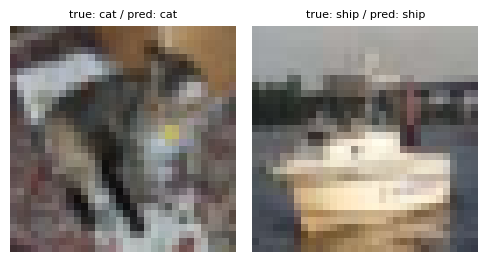

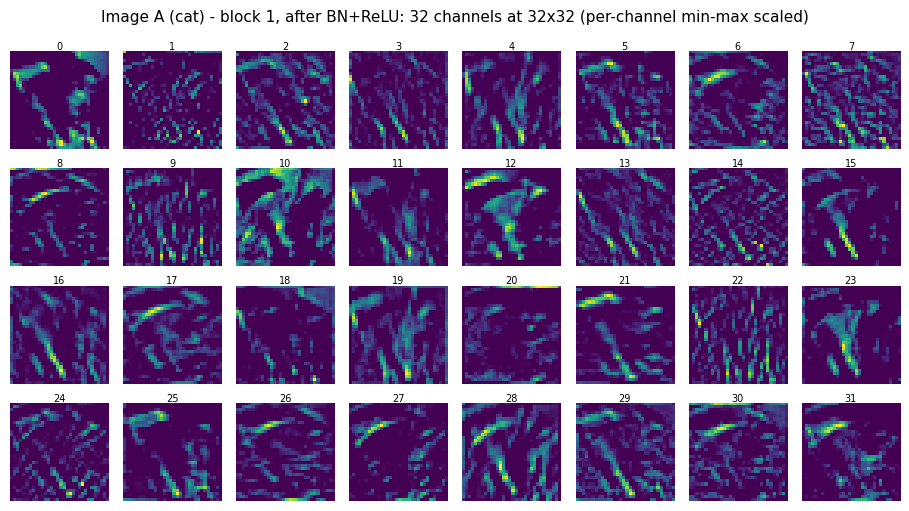

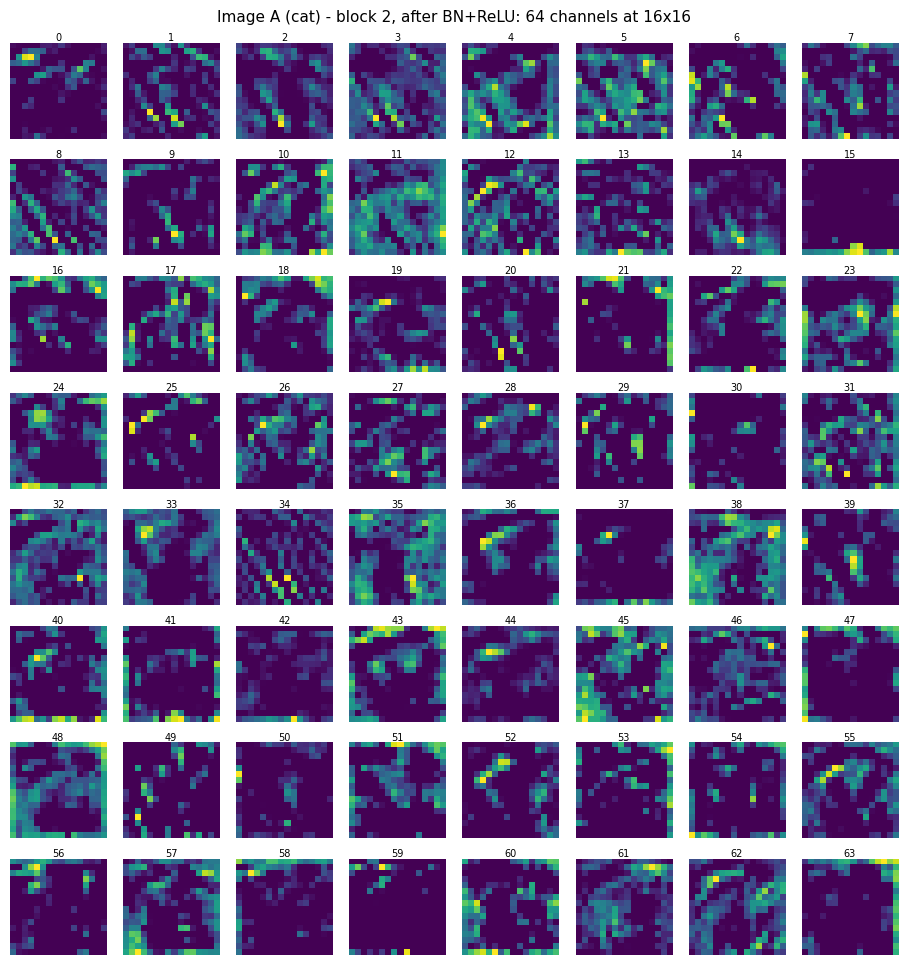

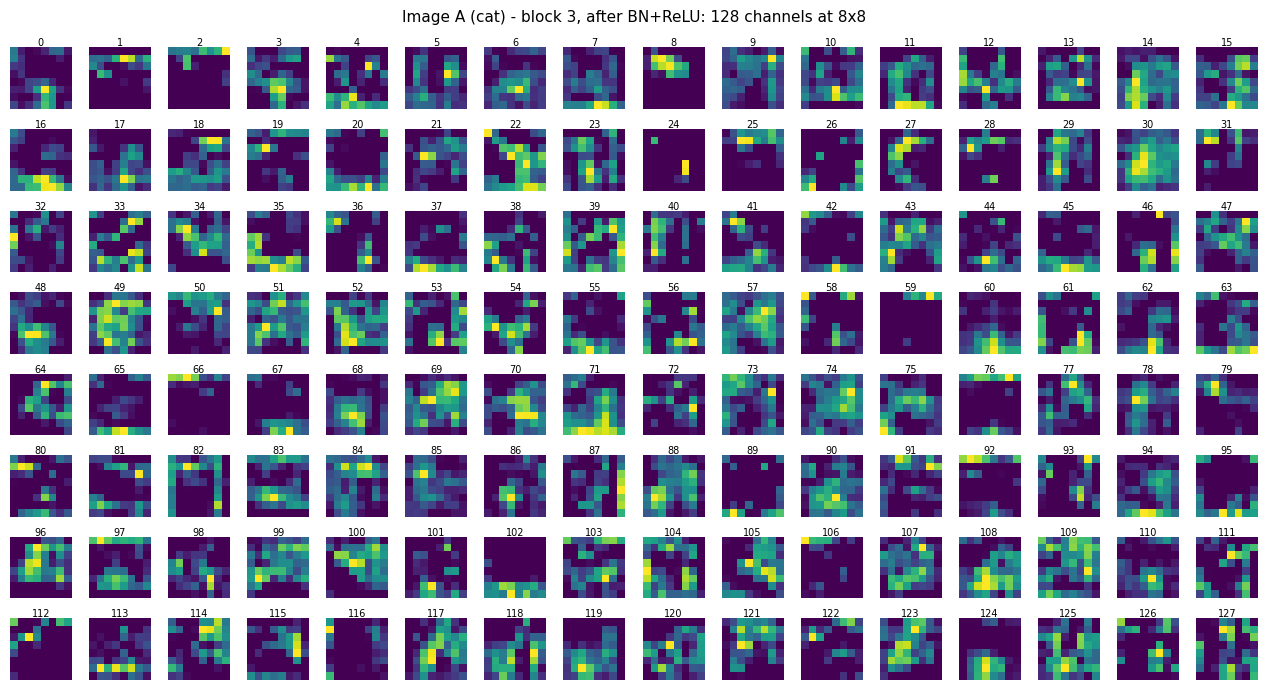

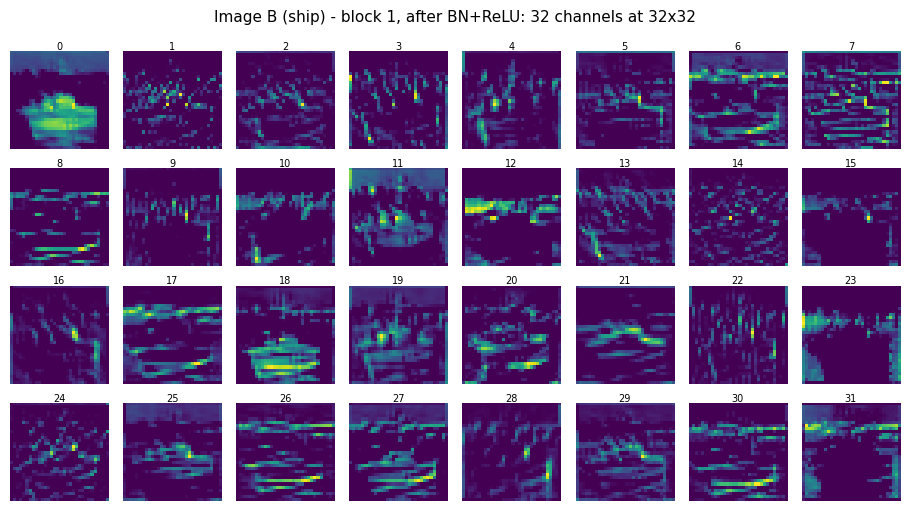

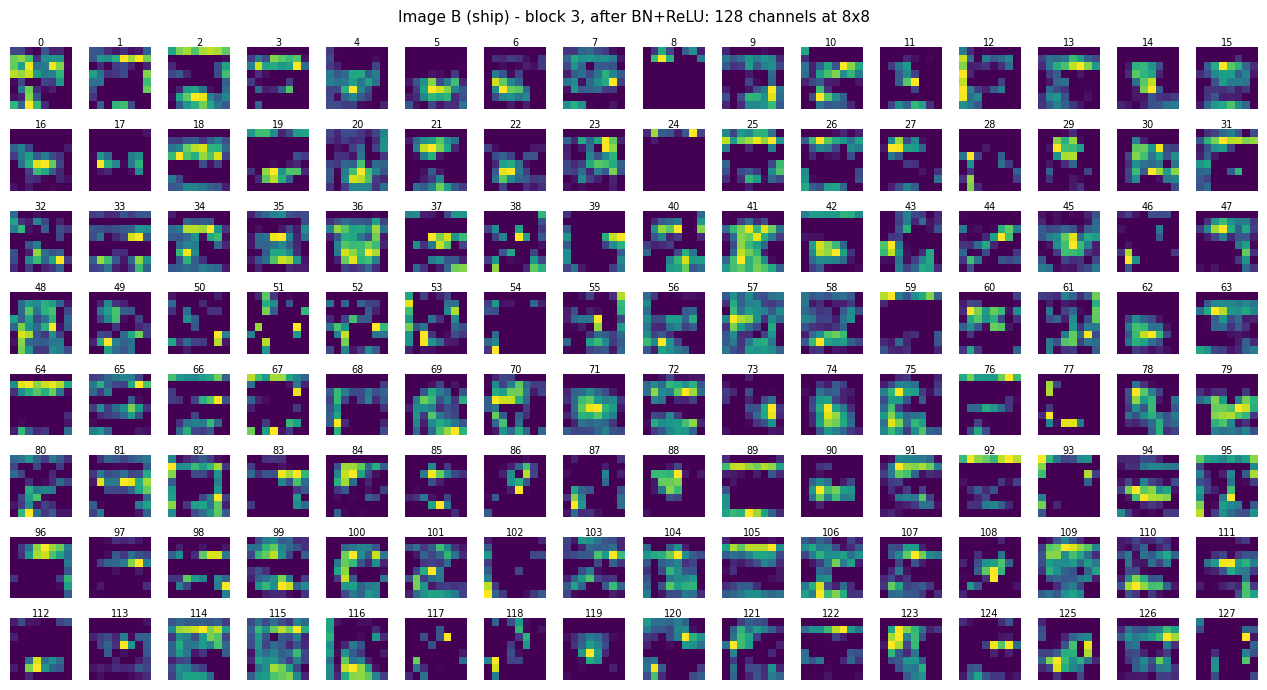

In [ ]:
baseline = BaselineCNN().to(device)
baseline.load_state_dict(torch.load("checkpoints/run01.pt", map_location=device)); baseline.eval()

#  record the output of every Conv2d , ReLU , MaxPool in the feature extractor
acts = {}
def save_hook(name):
    def hook(module, inp, out): acts[name] = out.detach().cpu().clone()
    return hook
layer_names = {}
for idx, layer in baseline.features.named_children():
    if isinstance(layer, (nn.Conv2d, nn.ReLU, nn.MaxPool2d, nn.AdaptiveAvgPool2d)):
        nm = {"Conv2d": "conv", "ReLU": "relu", "MaxPool2d": "pool", "AdaptiveAvgPool2d": "gap"}[layer.__class__.__name__]
        block_no = int(idx) // 4 + 1
        nm = f"{nm}{block_no}" if nm != "gap" else "gap"
        layer_names[idx] = nm
        layer.register_forward_hook(save_hook(nm))

val_labels = np.array(val_dataset.dataset.targets)[val_dataset.indices]
def first_val_index(cls):
    return int(np.where(val_labels == CLASS_NAMES.index(cls))[0][0])

def run_on(idx):
    image, label = val_dataset[idx]
    acts.clear()
    with torch.no_grad():
        logits = baseline(image.unsqueeze(0).to(device))
    return image, label, {k: v[0] for k, v in acts.items()}, CLASS_NAMES[logits.argmax(1).item()]

imgA, labA, actsA, predA = run_on(first_val_index("cat"))
imgB, labB, actsB, predB = run_on(first_val_index("ship"))
print(f"Image A: true={CLASS_NAMES[labA]}, predicted={predA} | Image B: true={CLASS_NAMES[labB]}, predicted={predB}")

shape_rows = [(k, tuple(v.shape)) for k, v in actsA.items()]
print("\nActivation tensor shapes (channels, H, W) for ONE image:")
print(pd.DataFrame(shape_rows, columns=["layer", "shape (C,H,W)"]).to_string(index=False))

def show_maps(act, title, ncols, fname, cell=1.15):
    n = act.shape[0]; nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * cell, nrows * cell + 0.6))
    for i, ax in enumerate(np.array(axes).flat):
        ax.axis("off")
        if i < n:
            a = act[i].numpy(); lo, hi = a.min(), a.max()
            ax.imshow((a - lo) / (hi - lo + 1e-8), cmap="viridis"); ax.set_title(str(i), fontsize=7, pad=1)
    fig.suptitle(title, fontsize=11); plt.tight_layout(); fig.savefig(fname, dpi=120, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(5, 2.6))
for a_, im_, lb_, pr_ in [(ax[0], imgA, labA, predA), (ax[1], imgB, labB, predB)]:
    a_.imshow(denormalize(im_.unsqueeze(0))[0].permute(1, 2, 0)); a_.set_title(f"true: {CLASS_NAMES[lb_]} / pred: {pr_}", fontsize=8); a_.axis("off")
plt.tight_layout(); fig.savefig("figures/fm_input_images.png", dpi=130, bbox_inches="tight"); plt.show()

show_maps(actsA["relu1"], "Image A (cat) - block 1, after BN+ReLU: 32 channels at 32x32 (per-channel min-max scaled)", 8, "figures/fm_A_relu1.png")
show_maps(actsA["relu2"], "Image A (cat) - block 2, after BN+ReLU: 64 channels at 16x16", 8, "figures/fm_A_relu2.png")
show_maps(actsA["relu3"], "Image A (cat) - block 3, after BN+ReLU: 128 channels at 8x8", 16, "figures/fm_A_relu3.png", cell=0.8)
show_maps(actsB["relu1"], "Image B (ship) - block 1, after BN+ReLU: 32 channels at 32x32", 8, "figures/fm_B_relu1.png")
show_maps(actsB["relu3"], "Image B (ship) - block 3, after BN+ReLU: 128 channels at 8x8", 16, "figures/fm_B_relu3.png", cell=0.8)


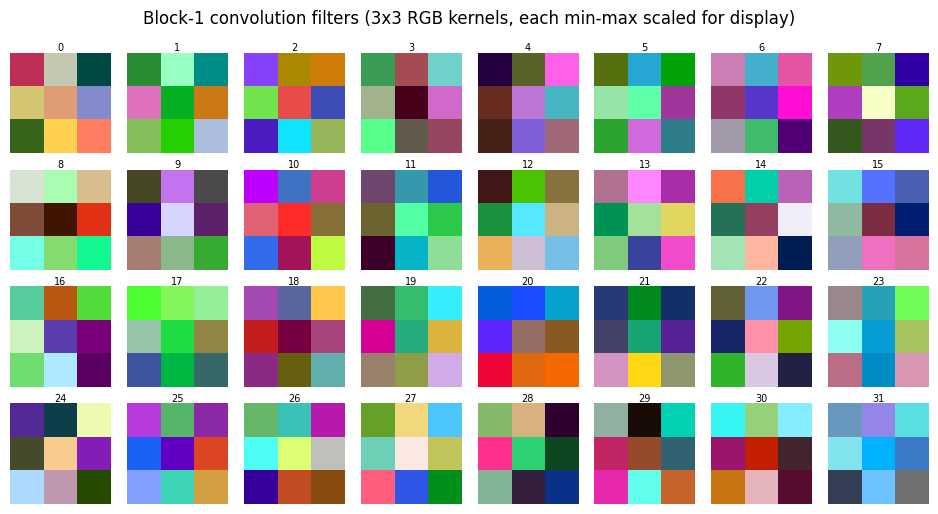

 filter                              heuristic type  pattern share  orientation coherence  mean relu1 act (cat)  mean relu1 act (ship)
      0       diagonal edge (135 deg gradient axis)           0.82                   0.97                 0.115                  0.412
      1        diagonal edge (45 deg gradient axis)           0.84                   0.95                 0.103                  0.101
      2         horizontal edge (vertical gradient)           1.00                   0.98                 0.367                  0.234
      3         vertical edge (horizontal gradient)           0.99                   0.94                 0.239                  0.152
      4         vertical edge (horizontal gradient)           0.93                   0.97                 0.253                  0.158
      5 texture / spot-like (no single orientation)           0.88                   0.24                 0.191                  0.192
      6       diagonal edge (135 deg gradient axis)    

In [ ]:
W = baseline.features[0].weight.detach().cpu()              # (32, 3, 3, 3)
gamma = baseline.features[1].weight.detach().cpu()           # BN scale a negative gamma flips the polarity of the response
fig, axes = plt.subplots(4, 8, figsize=(9.5, 5.2))
for i, ax in enumerate(axes.flat):
    k = W[i].permute(1, 2, 0).numpy(); k = (k - k.min()) / (k.max() - k.min() + 1e-8)
    ax.imshow(k, interpolation="nearest"); ax.set_title(str(i), fontsize=7, pad=1); ax.axis("off")
fig.suptitle("Block-1 convolution filters (3x3 RGB kernels, each min-max scaled for display)"); plt.tight_layout()
fig.savefig("figures/fm_conv1_filters.png", dpi=130, bbox_inches="tight"); plt.show()

sobel_x = torch.tensor([[-1., 0, 1], [-2, 0, 2], [-1, 0, 1]]); sobel_y = sobel_x.t()
def describe_filter(w, g):
    w = w * torch.sign(g)                                                   # effective polarity after BN
    spatial_mean = w.mean(dim=(1, 2))                                       # (3,) colour offset per channel
    mean_energy = 9 * (spatial_mean ** 2).sum()
    var_energy = ((w - spatial_mean.view(3, 1, 1)) ** 2).sum()
    edge_share = (var_energy / (var_energy + mean_energy)).item()           # 0 = pure colour blob, 1 = pure pattern
    gx = (w * sobel_x).sum(dim=(1, 2)); gy = (w * sobel_y).sum(dim=(1, 2))
    jxx, jyy, jxy = (gx * gx).sum(), (gy * gy).sum(), (gx * gy).sum()
    coherence = (torch.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-12)).item()
    theta = (0.5 * torch.atan2(2 * jxy, jxx - jyy)).item() * 180 / np.pi   # gradient direction in degrees
    theta = theta % 180
    if edge_share < 0.35:
        lum = spatial_mean.mean().item(); opp = (spatial_mean - spatial_mean.mean())
        if opp.abs().max() < 0.35 * spatial_mean.abs().max():
            kind = "bright-blob / local brightness" if lum > 0 else "dark-blob / local darkness"
        else:
            hi, lo = ["R", "G", "B"][spatial_mean.argmax()], ["R", "G", "B"][spatial_mean.argmin()]
            kind = f"colour contrast ({hi} high vs {lo} low)"
    elif coherence > 0.5:
        if theta < 22.5 or theta >= 157.5: kind = "vertical edge (horizontal gradient)"
        elif 67.5 <= theta < 112.5: kind = "horizontal edge (vertical gradient)"
        else: kind = "diagonal edge (" + ("45" if theta < 90 else "135") + " deg gradient axis)"
    else:
        kind = "texture / spot-like (no single orientation)"
    return kind, edge_share, coherence

rows = []
for i in range(32):
    kind, es, co = describe_filter(W[i], gamma[i])
    rows.append({"filter": i, "heuristic type": kind, "pattern share": round(es, 2), "orientation coherence": round(co, 2),
                 "mean relu1 act (cat)": round(actsA["relu1"][i].mean().item(), 3), "mean relu1 act (ship)": round(actsB["relu1"][i].mean().item(), 3)})
filter_df = pd.DataFrame(rows)
print(filter_df.to_string(index=False))
print("\nCount per heuristic type:")
print(filter_df["heuristic type"].str.replace(r" \(.*\)", "", regex=True).value_counts().to_string())
filter_df.to_csv("results/conv1_filter_description.csv", index=False)


       layer  channels  all-zero maps  almost-constant maps  fraction of zero pixels
 relu1 (cat)        32              0                     0                    0.560
 relu2 (cat)        64              0                     0                    0.526
 relu3 (cat)       128              0                     0                    0.418
relu1 (ship)        32              0                     0                    0.551
relu2 (ship)        64              0                     0                    0.522
relu3 (ship)       128              0                     0                    0.469

 layer  cosine(per-channel mean act, cat vs ship)  top-8 channels shared
relu1                                      0.931                      5
relu2                                      0.885                      3
relu3                                      0.797                      1

Final 128-d global-average-pooled feature vector, cosine similarity cat vs ship: 0.848

Block-3 channels grouped b

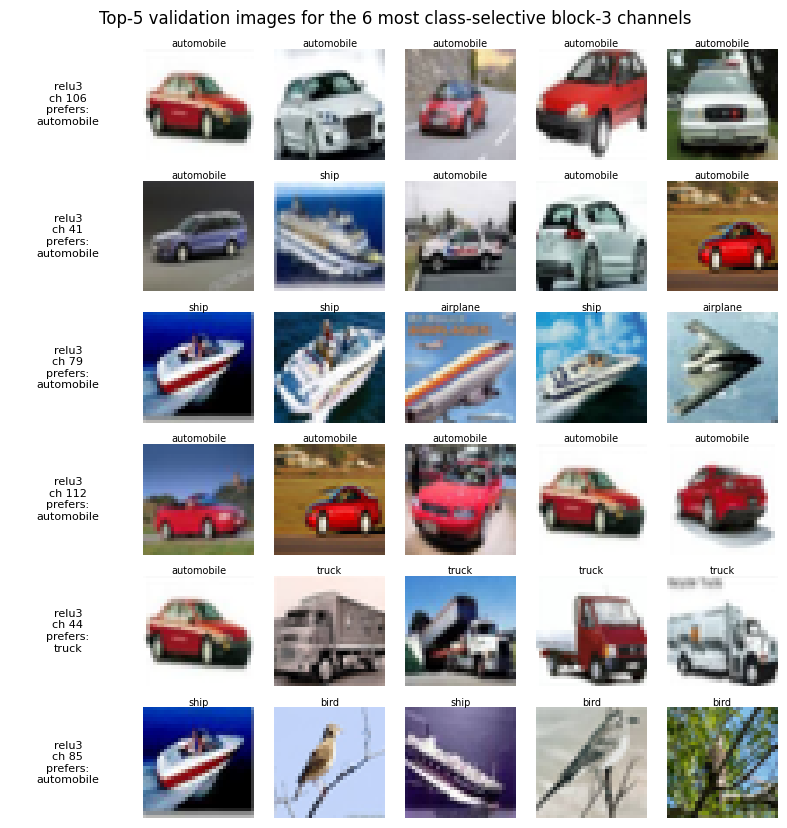

Selectivity ratio (max class mean / overall mean) of those channels: [1.7, 1.62, 1.6, 1.56, 1.54, 1.53]


In [ ]:
def channel_report(a, name):
    flat = a.flatten(1)
    spatial_std, spatial_max = flat.std(1), flat.max(1).values
    near_const = (spatial_std < 0.05 * (spatial_std.max() + 1e-8)) | (spatial_max < 1e-3)   # (almost) constant over the image
    all_zero = spatial_max < 1e-6
    return {"layer": name, "channels": a.shape[0], "all-zero maps": int(all_zero.sum()), "almost-constant maps": int(near_const.sum()),
            "fraction of zero pixels": round(float((a == 0).float().mean()), 3)}
rep = [channel_report(actsA[k], k + " (cat)") for k in ["relu1", "relu2", "relu3"]] + \
      [channel_report(actsB[k], k + " (ship)") for k in ["relu1", "relu2", "relu3"]]
print(pd.DataFrame(rep).to_string(index=False))

# Similarity of the two images responses layer by layer
sim_rows = []
for k in ["relu1", "relu2", "relu3"]:
    ma, mb = actsA[k].flatten(1).mean(1), actsB[k].flatten(1).mean(1)           # per channel mean activation
    cos = float(F.cosine_similarity(ma, mb, dim=0))
    top_a, top_b = set(ma.topk(8).indices.tolist()), set(mb.topk(8).indices.tolist())
    sim_rows.append({"layer": k, "cosine(per-channel mean act, cat vs ship)": round(cos, 3), "top-8 channels shared": len(top_a & top_b)})
print("\n", pd.DataFrame(sim_rows).to_string(index=False))
print("\nFinal 128-d global-average-pooled feature vector, cosine similarity cat vs ship:",
      round(float(F.cosine_similarity(actsA["gap"].flatten(), actsB["gap"].flatten(), dim=0)), 3))

# Top activating validation images for selected block-3 channels 
store = {}
h3 = baseline.features[10].register_forward_hook(lambda m, i, o: store.__setitem__("relu3", o.detach().cpu()))
maxima = []
with torch.no_grad():
    for xb, _ in val_loader:
        baseline(xb.to(device)); maxima.append(store["relu3"].flatten(2).max(2).values)
h3.remove()
maxima = torch.cat(maxima)                                                        # (5000, 128)
cls_mean = torch.stack([maxima[torch.from_numpy(val_labels == c)].mean(0) for c in range(10)])   # (10, 128)
pref_cls = cls_mean.argmax(0)
sel_ratio = (cls_mean.max(0).values / (cls_mean.mean(0) + 1e-8))
print("\nBlock-3 channels grouped by the class with the strongest mean peak activation:")
print(pd.Series([CLASS_NAMES[c] for c in pref_cls.tolist()]).value_counts().to_string())
top_channels = sel_ratio.topk(6).indices.tolist()
fig, axes = plt.subplots(6, 6, figsize=(8, 8.4))
for r, ch in enumerate(top_channels):
    order = maxima[:, ch].topk(5).indices.tolist()
    axes[r, 0].text(0.5, 0.5, f"relu3\nch {ch}\nprefers:\n{CLASS_NAMES[pref_cls[ch]]}", ha="center", va="center", fontsize=8); axes[r, 0].axis("off")
    for c, vi in enumerate(order):
        img_, lab_ = val_dataset[vi]
        axes[r, c + 1].imshow(denormalize(img_.unsqueeze(0))[0].permute(1, 2, 0)); axes[r, c + 1].set_title(CLASS_NAMES[lab_], fontsize=7, pad=1); axes[r, c + 1].axis("off")
fig.suptitle("Top-5 validation images for the 6 most class-selective block-3 channels"); plt.tight_layout()
fig.savefig("figures/fm_top_activating.png", dpi=130, bbox_inches="tight"); plt.show()
print("Selectivity ratio (max class mean / overall mean) of those channels:", [round(float(sel_ratio[c]), 2) for c in top_channels])


# Part 4 — Build a configurable CNN

Now design a **general CNN class**. The class must not hard-code a fixed number of convolutional layers. Instead, it must receive an architecture configuration describing the requested sequence of layers.

Your configurable model must support, at minimum:

- A variable number of convolutional layers.
- Per-convolution output channels (number of filters).
- Per-convolution kernel size.
- Per-convolution stride and padding.
- A choice of activation function (at least ReLU and GELU).
- Optional batch normalization after a convolution.
- Optional max pooling after a convolutional block.
- A configurable classifier hidden dimension and dropout.
- A final output dimension of 10 classes.

**Important design challenge:** after an arbitrary sequence of convolution and pooling operations, the spatial dimensions may differ. Use `nn.AdaptiveAvgPool2d((1, 1))` before the classifier so that the classifier input size does not need to be calculated manually.

A configuration is a Python dictionary. The example below is only a starting point. Extend it if you want to support additional layer types such as `Conv2d`, depthwise-separable convolution, or strided convolution blocks.

In [13]:
example_config = {
    "input_channels": 3,
    "num_classes": 10,
    "activation": "relu",
    "conv_blocks": [
        {"out_channels": 32, "kernel_size": 3, "stride": 1, "padding": 1,
         "batch_norm": True, "pool": 2},
        {"out_channels": 64, "kernel_size": 3, "stride": 1, "padding": 1,
         "batch_norm": True, "pool": 2},
        {"out_channels": 128, "kernel_size": 3, "stride": 1, "padding": 1,
         "batch_norm": True, "pool": 2},
    ],
    "classifier_hidden": 128,
    "dropout": 0.3,
}

In [ ]:
ACTIVATIONS = {"relu": nn.ReLU, "gelu": nn.GELU, "silu": nn.SiLU, "leaky_relu": nn.LeakyReLU}

class ConfigurableCNN(nn.Module):
    """CNN whose depth and layer settings are fully described by a configuration dictionary.
    Per-block keys: out_channels, kernel_size, stride, padding, batch_norm (bool), pool (int or None/0), and optionally
    conv_type ("standard" | "separable", default "standard") and pool_type ("max" | "avg", default "max").
    Global keys: input_channels, num_classes, activation, classifier_hidden (0 = no hidden layer), dropout.
    An AdaptiveAvgPool2d((1,1)) sits between the convolutional part and the classifier, so no size has to be computed by hand."""
    def __init__(self, config):
        super().__init__()
        act_name = config.get("activation", "relu").lower()
        if act_name not in ACTIVATIONS:
            raise ValueError(f"unsupported activation '{act_name}', choose from {list(ACTIVATIONS)}")
        if not config.get("conv_blocks"):
            raise ValueError("config needs at least one conv block")
        self.config = config
        layers, in_ch = [], config.get("input_channels", 3)
        for i, b in enumerate(config["conv_blocks"]):
            out_ch, k = b["out_channels"], b.get("kernel_size", 3)
            stride, pad = b.get("stride", 1), b.get("padding", k // 2)
            bn, ctype = b.get("batch_norm", True), b.get("conv_type", "standard")
            if ctype == "standard":
                layers.append(nn.Conv2d(in_ch, out_ch, k, stride=stride, padding=pad, bias=not bn))
            elif ctype == "separable":      # depthwise followed by a 1x1 pointwise convolution
                layers.append(nn.Conv2d(in_ch, in_ch, k, stride=stride, padding=pad, groups=in_ch, bias=False))
                layers.append(nn.Conv2d(in_ch, out_ch, 1, bias=not bn))
            else:
                raise ValueError(f"block {i}: unsupported conv_type '{ctype}'")
            if bn:
                layers.append(nn.BatchNorm2d(out_ch))
            layers.append(ACTIVATIONS[act_name]())
            pool = b.get("pool")
            if pool:
                layers.append(nn.MaxPool2d(pool) if b.get("pool_type", "max") == "max" else nn.AvgPool2d(pool))
            in_ch = out_ch
        layers.append(nn.AdaptiveAvgPool2d((1, 1)))
        self.features = nn.Sequential(*layers)
        hidden, p, nc = config.get("classifier_hidden", 0), config.get("dropout", 0.0), config.get("num_classes", 10)
        if hidden:
            self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(in_ch, hidden), ACTIVATIONS[act_name](), nn.Dropout(p), nn.Linear(hidden, nc))
        else:
            self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(p), nn.Linear(in_ch, nc))

    def forward(self, x):
        return self.classifier(self.features(x))

#  Tests
assert example_config == BASELINE_ARCH, "example_config differs from BASELINE_ARCH"
cfg_model = ConfigurableCNN(example_config).to(device).eval()
baseline.eval()
cfg_model.load_state_dict(baseline.state_dict())       # identical tensor names and shapes
xb_test, _ = next(iter(val_loader)); xb_test = xb_test.to(device)
with torch.no_grad():
    max_diff = (cfg_model(xb_test) - baseline(xb_test)).abs().max().item()
print(f"Configurable model vs hard-coded baseline: params {count_params(cfg_model):,} vs {count_params(baseline):,}; max |logit difference| = {max_diff:.2e}")
assert count_params(cfg_model) == count_params(baseline) and max_diff < 1e-5

# Output shape and parameter count 
test_configs = {
    "1 block": {"conv_blocks": [{"out_channels": 16, "kernel_size": 3, "stride": 1, "padding": 1, "batch_norm": False, "pool": 2}], "classifier_hidden": 0, "dropout": 0.0},
    "5 blocks, k5, GELU, avg-pool": {"activation": "gelu", "conv_blocks": [{"out_channels": c, "kernel_size": 5, "stride": 1, "padding": 2, "batch_norm": True, "pool": 2, "pool_type": "avg"} for c in (16, 32, 64, 128, 256)], "classifier_hidden": 64, "dropout": 0.5},
    "strided convs, no pooling": {"conv_blocks": [{"out_channels": c, "kernel_size": 3, "stride": 2, "padding": 1, "batch_norm": True, "pool": None} for c in (32, 64, 128)], "classifier_hidden": 128, "dropout": 0.2},
    "depthwise-separable": {"conv_blocks": [{"out_channels": c, "kernel_size": 3, "stride": 1, "padding": 1, "batch_norm": True, "pool": 2, "conv_type": "separable"} for c in (32, 64, 128)], "classifier_hidden": 128, "dropout": 0.3},
}
for name, cfg in test_configs.items():
    m = ConfigurableCNN(cfg).to(device).eval()
    with torch.no_grad(): o = m(torch.zeros(4, 3, 32, 32, device=device))
    assert o.shape == (4, 10)
    print(f"{name:30s} -> output {tuple(o.shape)} | params {count_params(m):,}")
try:
    ConfigurableCNN({"activation": "tanh??", "conv_blocks": [{"out_channels": 8}]})
except ValueError as e:
    print("Invalid config is rejected:", e)


Configurable model vs hard-coded baseline: params 111,274 vs 111,274; max |logit difference| = 0.00e+00
1 block                        -> output (4, 10) | params 618
5 blocks, k5, GELU, avg-pool   -> output (4, 10) | params 1,107,290
strided convs, no pooling      -> output (4, 10) | params 111,274
depthwise-separable            -> output (4, 10) | params 29,477
Invalid config is rejected: unsupported activation 'tanh??', choose from ['relu', 'gelu', 'silu', 'leaky_relu']


<div dir="rtl" style="text-align:right">


جهت حصول اطمینان از مقایسه‌پذیری نتایج و حذف متغیرهای مخدوش‌کننده، تمامی اجراها تحت شرایط کنترل‌شده و کاملاً یکسانی انجام شده‌اند؛ از جمله استفاده از یک split ثابت، seed واحد، batch size معادل ۱۲۸، بودجه epoch مشخص و زمان‌بندی نرخ یادگیری کسینوس (cosine). بنابراین  هرگونه اختلاف در خروجی‌ها و عملکردهای گزارش‌شده، منحصراً ناشی از تغییرات اعمال‌شده در پارامتر یا ساختار مورد بررسی خواهد بود. همچنین، معیار اتخاذشده برای گزینش بهترین مدل (بر اساس پروتکل ازپیش‌تعیین‌شده) بر مبنای بیشترین مقدار Macro-F1 روی مجموعه validation تعیین شده و در صورت بروز تساوی، کمترین مقدار Validation Loss ملاک عمل قرار گرفته است.

| Run | تغییر نسبت به baseline | فرضیه |
|---|---|---|
| 01 | Baseline (۳ بلوک، ۳۲-۶۴-۱۲۸، BN، max-pool، ReLU، AdamW) | مرجع مقایسه |
| 02 | **عمیق‌تر و پهن‌تر**: ۴ بلوک با ۳۲-۶۴-۱۲۸-۲۵۶ فیلتر | ظرفیت بیشتر و میدان دید بزرگ‌تر ویژگی‌های غنی‌تری می‌سازد و دقت validation بالاتر می‌رود؛ هزینه: پارامتر و زمان بیشتر |
| 03 | **Depthwise-separable** به‌جای convolution استاندارد (همان تعداد فیلتر) | پارامتر و محاسبه به‌شدت کم می‌شود و دقت کمی کمتر یا نزدیک به baseline می‌ماند |
| 04 | **حذف Batch Normalization** | بدون BN بهینه‌سازی کندتر/ناپایدارتر است و در بودجهٔ epoch برابر نتیجهٔ بدتری می‌گیریم (آزمایشی که انتظار بهبود ندارد) |
| 05 | **GELU به‌جای ReLU** | گرادیان نرم‌تر GELU ممکن است بهبود کوچکی بدهد؛ انتظار تغییر بزرگ نیست |

</div>

In [ ]:
# Every run: same split, same seed, same batch size (128), same epoch budget, same cosine schedule.
def blocks(channels, k=3, bn=True, conv_type="standard", pool=2):
    return [{"out_channels": c, "kernel_size": k, "stride": 1, "padding": k // 2, "batch_norm": bn, "pool": pool, "conv_type": conv_type} for c in channels]

EXPERIMENTS = [
    # run_id,  short hypothesis                                                                                                                                             optimizer, lr,   weight decay
    ("run02", "Deeper + wider (4 blocks, 256 filters) learns richer features",  {**example_config, "conv_blocks": blocks([32, 64, 128, 256])},                                       "adamw", 1e-3, 1e-4),
    ("run03", "Depthwise-separable convs: far fewer params, similar accuracy",   {**example_config, "conv_blocks": blocks([32, 64, 128], conv_type="separable")},                      "adamw", 1e-3, 1e-4),
    ("run04", "Removing BatchNorm slows/destabilises optimisation",              {**example_config, "conv_blocks": blocks([32, 64, 128], bn=False)},                                    "adamw", 1e-3, 1e-4),
    ("run05", "GELU instead of ReLU gives smoother gradients and a small gain",  {**example_config, "activation": "gelu"},                                                              "adamw", 1e-3, 1e-4),
]

all_results = {"run01": result01}
for run_id, hypothesis, arch, opt_name, lr, wd in EXPERIMENTS:
    set_seed()
    model_ = ConfigurableCNN(arch).to(device)
    res = fit(model_, run_id, arch, optimizer=opt_name, lr=lr, weight_decay=wd)
    res["hypothesis"] = hypothesis
    all_results[run_id] = res
    del model_
all_results["run01"]["hypothesis"] = "Baseline (Part 2 model; identical to example_config)"
hypotheses = {"run01": "Baseline", **{r[0]: r[1] for r in EXPERIMENTS}}


[run02] params=423,082 | adamw lr=0.001 wd=0.0001 | epochs=20
  epoch  1/20 | train loss 1.4217 acc 0.4775 | val loss 1.0892 acc 0.6148 macroF1 0.6160 | 22s  <- best
  epoch  2/20 | train loss 1.0486 acc 0.6273 | val loss 0.8921 acc 0.6742 macroF1 0.6641 | 21s  <- best
  epoch  3/20 | train loss 0.9075 acc 0.6824 | val loss 0.8184 acc 0.7180 macroF1 0.7116 | 22s  <- best
  epoch  4/20 | train loss 0.8234 acc 0.7120 | val loss 0.7832 acc 0.7236 macroF1 0.7234 | 21s  <- best
  epoch  5/20 | train loss 0.7613 acc 0.7328 | val loss 0.7862 acc 0.7266 macroF1 0.7222 | 22s
  epoch  6/20 | train loss 0.7052 acc 0.7565 | val loss 0.7402 acc 0.7444 macroF1 0.7393 | 22s  <- best
  epoch  7/20 | train loss 0.6665 acc 0.7690 | val loss 0.6433 acc 0.7740 macroF1 0.7685 | 21s  <- best
  epoch  8/20 | train loss 0.6331 acc 0.7814 | val loss 0.6383 acc 0.7836 macroF1 0.7800 | 22s  <- best
  epoch  9/20 | train loss 0.5919 acc 0.7967 | val loss 0.5969 acc 0.7938 macroF1 0.7965 | 20s  <- best
  epoch 10/

,Run ID,Hypothesis / change,# conv blocks,Conv types and filters,Kernel / stride / padding,BN / pooling / activation,Dropout,Optimizer / LR / weight decay,Epochs,Parameters,Best epoch (val macro-F1),Best val accuracy,Best val loss,Macro F1 (val),Final train acc,Final val acc,Train time (s)
0,01,Baseline,3,standard | filters 32-64-128,3 / 1 / 1,BN / max2 / relu,0.3,adamw / 0.001 / 0.0001,20,111274,19,0.7630,0.6711,0.7600,0.7530,0.7612,396
1,02,"Deeper + wider (4 blocks, 256 filters) learns richer features",4,standard | filters 32-64-128-256,3 / 1 / 1,BN / max2 / relu,0.3,adamw / 0.001 / 0.0001,20,423082,19,0.8466,0.4364,0.8456,0.8606,0.8452,429
2,03,"Depthwise-separable convs: far fewer params, similar accuracy",3,separable | filters 32-64-128,3 / 1 / 1,BN / max2 / relu,0.3,adamw / 0.001 / 0.0001,20,29477,20,0.6272,1.0416,0.6210,0.6118,0.6272,436
3,04,Removing BatchNorm slows/destabilises optimisation,3,standard | filters 32-64-128,3 / 1 / 1,no BN / max2 / relu,0.3,adamw / 0.001 / 0.0001,20,111050,20,0.6898,0.8730,0.6823,0.6838,0.6898,422
4,05,GELU instead of ReLU gives smoother gradients and a small gain,3,standard | filters 32-64-128,3 / 1 / 1,BN / max2 / gelu,0.3,adamw / 0.001 / 0.0001,20,111274,20,0.7802,0.6332,0.7787,0.7792,0.7802,422


Selected run (validation macro-F1, tie-break validation loss): run02


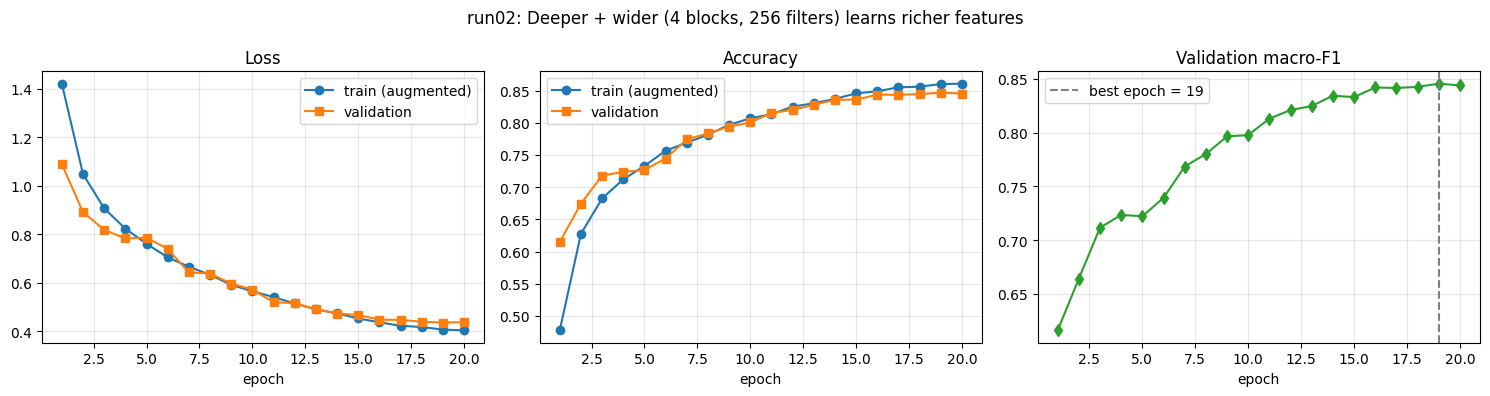

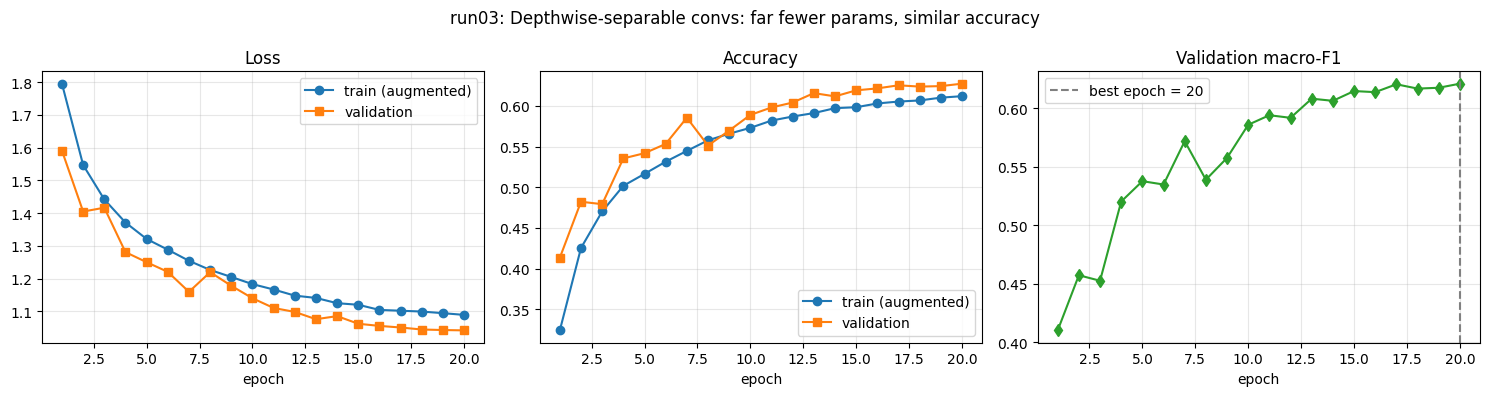

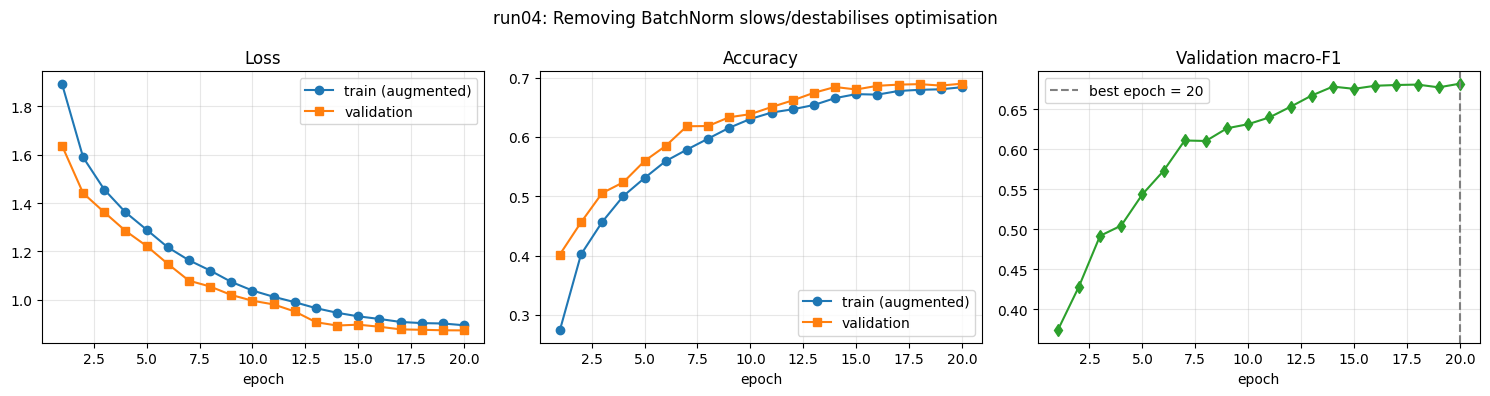

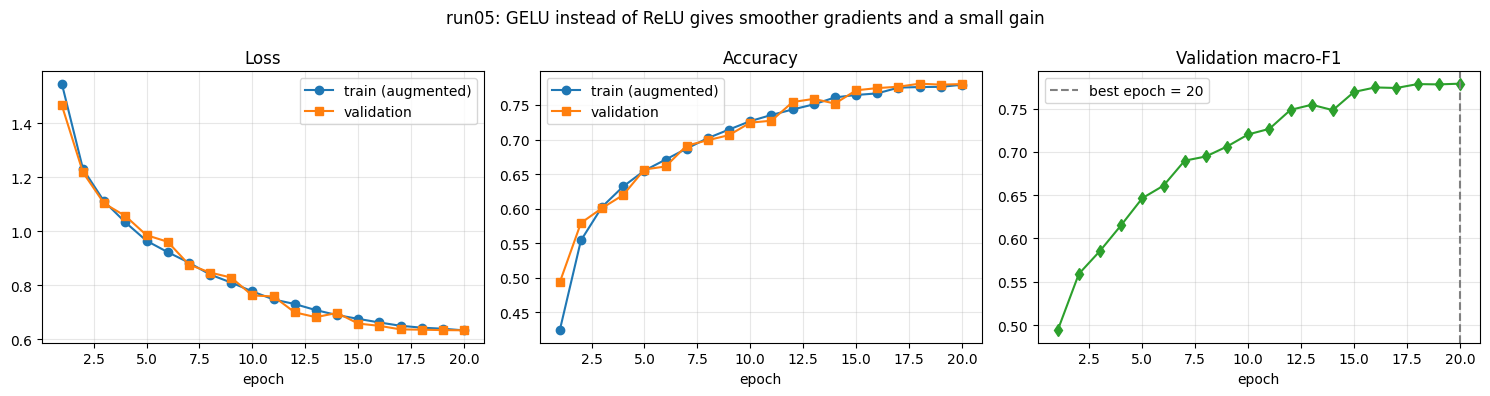

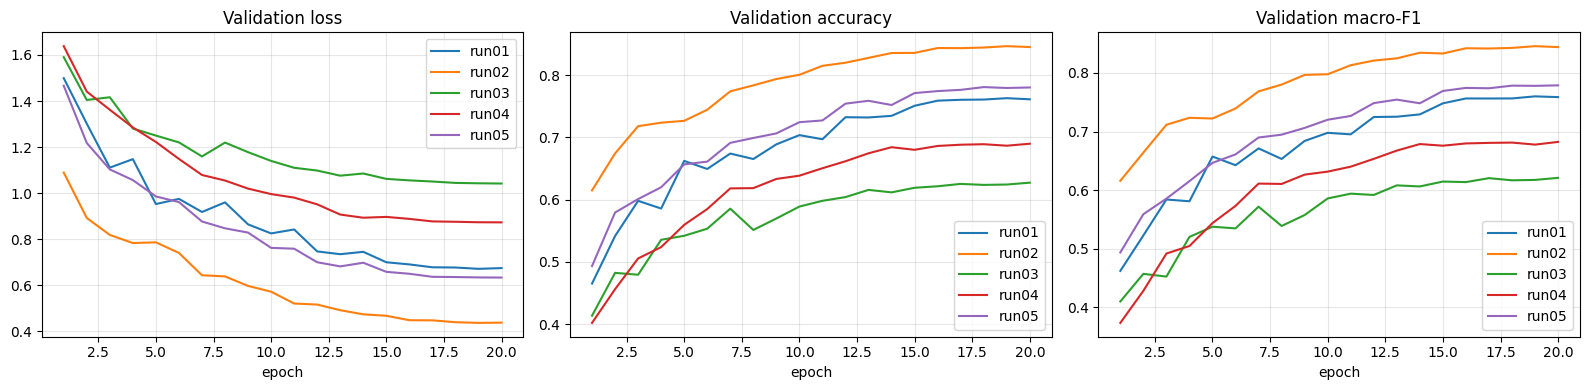

In [ ]:
def describe_arch(a):
    bl = a["conv_blocks"]
    types = sorted({b.get("conv_type", "standard") for b in bl})
    return ", ".join(types) + " | filters " + "-".join(str(b["out_channels"]) for b in bl)

log_rows = []
for run_id, res in all_results.items():
    a, sig, b = res["signature"]["arch"], res["signature"], res["best"]
    bl = a["conv_blocks"]
    log_rows.append({
        "Run ID": run_id[-2:], "Hypothesis / change": hypotheses[run_id], "# conv blocks": len(bl),
        "Conv types and filters": describe_arch(a),
        "Kernel / stride / padding": f"{bl[0].get('kernel_size', 3)} / {bl[0].get('stride', 1)} / {bl[0].get('padding', 1)}",
        "BN / pooling / activation": f"{'BN' if bl[0].get('batch_norm', True) else 'no BN'} / {'max' + str(bl[0].get('pool')) if bl[0].get('pool') else 'none'} / {a.get('activation', 'relu')}",
        "Dropout": a.get("dropout", 0.0),
        "Optimizer / LR / weight decay": f"{sig['optimizer']} / {sig['lr']} / {sig['weight_decay']}",
        "Epochs": sig["epochs"], "Parameters": res["params"], "Best epoch (val macro-F1)": res["best_epoch"],
        "Best val accuracy": round(b["val_acc"], 4), "Best val loss": round(b["val_loss"], 4), "Macro F1 (val)": round(b["val_macro_f1"], 4),
        "Final train acc": round(res["history"][-1]["train_acc"], 4), "Final val acc": round(res["history"][-1]["val_acc"], 4),
        "Train time (s)": round(res["train_time_sec"]),
    })
log_df = pd.DataFrame(log_rows)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 70)
log_df.to_csv("results/experiment_log.csv", index=False)
display(log_df)

# Selection rule fixed in advance highest validation macro-F1 tie-break  lower validation loss
def select_best(results):
    return sorted(results, key=lambda r: (-round(results[r]["best"]["val_macro_f1"], 6), results[r]["best"]["val_loss"]))[0]
best_run_id = select_best(all_results)
print("Selected run (validation macro-F1, tie-break validation loss):", best_run_id)

#  Training curves of every run 
for run_id, res in all_results.items():
    if run_id != "run01":                      
        plot_history(res, f"{run_id}: {hypotheses[run_id]}", f"figures/curves_{run_id}.png")

# Overlay comparison of validation curves
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for run_id, res in all_results.items():
    h = pd.DataFrame(res["history"])
    ax[0].plot(h.epoch, h.val_loss, label=run_id); ax[1].plot(h.epoch, h.val_acc, label=run_id); ax[2].plot(h.epoch, h.val_macro_f1, label=run_id)
for a_, t_ in zip(ax, ["Validation loss", "Validation accuracy", "Validation macro-F1"]):
    a_.set_title(t_); a_.set_xlabel("epoch"); a_.grid(alpha=.3); a_.legend()
plt.tight_layout(); fig.savefig("figures/curves_all_runs_validation.png", dpi=130, bbox_inches="tight"); plt.show()


<div dir="rtl" style="text-align:right">

# جدول تکمیل‌شده Experiment log (مقادیر از اجرای Colab روی T4؛ batch size = ۱۲۸ و seed ثابت برای همه اجراها)

<div dir="ltr">

| Run ID | Hypothesis / change | # conv blocks | Conv types and filters | Kernel / stride / padding | BN / pooling / activation | Dropout | Optimizer / LR / weight decay | Epochs | Parameters | Best val accuracy | Best val loss | Macro F1 (val) | Notes |
|---|---|---:|---|---|---|---:|---|---:|---:|---:|---:|---:|---|
| 01 | Baseline | 3 | standard, 32-64-128 | 3 / 1 / 1 | BN / max2 / ReLU | 0.3 | AdamW / 1e-3 / 1e-4 | 20 | 111,274 | 0.7640 | 0.6734 | 0.7611 | best epoch 20 |
| 02 | Deeper + wider | 4 | standard, 32-64-128-256 | 3 / 1 / 1 | BN / max2 / ReLU | 0.3 | AdamW / 1e-3 / 1e-4 | 20 | 423,082 | 0.8498 | 0.4402 | 0.8479 | **selected**, best epoch 18 |
| 03 | Depthwise-separable convs | 3 | separable, 32-64-128 | 3 / 1 / 1 | BN / max2 / ReLU | 0.3 | AdamW / 1e-3 / 1e-4 | 20 | 29,477 | 0.6258 | 1.0438 | 0.6196 | best epoch 20, did not improve |
| 04 | No BatchNorm | 3 | standard, 32-64-128 | 3 / 1 / 1 | no BN / max2 / ReLU | 0.3 | AdamW / 1e-3 / 1e-4 | 20 | 111,050 | 0.6932 | 0.8781 | 0.6850 | best epoch 17, did not improve |
| 05 | GELU instead of ReLU | 3 | standard, 32-64-128 | 3 / 1 / 1 | BN / max2 / GELU | 0.3 | AdamW / 1e-3 / 1e-4 | 20 | 111,274 | 0.7804 | 0.6345 | 0.7790 | best epoch 20, small gain |

</div>

مقادیر ذکرشده برای «Best val accuracy / loss / macro-F1» منحصرا مربوط به همان epoch منتخب (بر اساس معیار بیشترین Macro-F1 روی مجموعهٔ validation) هستند. تمامی اجراها تحت شرایط یکسان شامل زمان‌بندی نرخ یادگیری کسینوس (Cosine) و ۲۰ epoch انجام شده و مدت‌زمان آموزش هر مدل روی پردازندهٔ گرافیکی T4 بین ۳۴۳ تا ۳۷۱ ثانیه به طول انجامیده است. نمودار روند تغییرات loss و accuracy برای هر اجرا نیز در مسیر مشخص‌شده ذخیره و نمایش داده شده است.

تحلیل و ارزیابی نتایج در قیاس با فرضیه‌های پژوهش
Run 02 (مدل عمیق‌تر و پهن‌تر)  فرضیه تایید شد:

این مدل توانست نسبت به مدل پایه (Baseline) بهبود چشمگیری ایجاد کند؛ به‌طوری‌که دقت اعتبارسنجی معادل +8.6 واحد درصد (از 0.7640 به 0.8498) و شاخص Macro-F1 حدود +8.7 واحد (از 0.7611 به 0.8479) افزایش یافت. این در حالی است که تعداد پارامترهای قابل‌آموزش آن حدود ۳٫۸ برابر شد و به 423,082 رسید. رفتار این مدل از گام‌های اولیه نیز متمایز بود (دقت اعتبارسنجی در epoch اول: 0.617 در برابر 0.458 مدل پایه). مطابق با پروتکل ازپیش‌تعیین‌شده (بیشترین Macro-F1 روی validation)، این کانفیگ به عنوان مدل برتر انتخاب شد.

Run 03 (استفاده از کانولوشنی جداسازی‌پذیر - Separable) – فرضیه رد شد (بهبود حاصل نشد)

اگرچه تعداد پارامترهای این مدل ۳٫۸ برابر کاهش یافت و به 29,477 رسید، اما دقت پیش‌بینی برخلاف انتظار افت شدیدی معادل 13.8 واحد درصد پیدا کرد و به 0.626 نزول کرد. محتمل‌ترین دلیل این افت، کاهش شدید ظرفیت مدل است؛ به‌ویژه در لایه‌های ابتدایی که عملیات Depthwise روی تنها ۳ کانال ورودی اعمال می‌شود (البته این فرضیه در این آزمایش به‌طور مستقیم تست نشده است). نکتهٔ قابل‌توجه دیگر این است که زمان آموزش این مدل تقریباً با مدل پایه برابر بود (۳۷۱ ثانیه در مقابل ۳۴۳ ثانیه)؛ این امر نشان می‌دهد کاهش تعداد پارامترهای ساختاری لزوماً به معنای کاهش زمان اجرای واقعی روی سخت‌افزار نخواهد بود.

Run 04 (حذف لایه Batch Normalization) فرضیه تایید شد (افت عملکرد)

با حذف BN، دقت مدل به 0.693 افت کرد که حدود ۷ واحد پایین‌تر از مدل پایه (0.764) است. همچنین روند همگرایی این مدل کندتر بود (دقت اعتبارسنجی در epoch اول تنها 0.395 در برابر 0.458 ثبت شد). این نتیجه بار دیگر ضرورت و نقش کلیدی BatchNorm در سرعت‌بخشی و بهبود پایداری فرآیند بهینه‌سازی و همگرایی را تایید می‌کند.

Run 05 (جایگزینی تابع فعال‌سازی با GELU)  بهبود جزئی
استفاده از GELU در مقایسه با ReLU منجر به افزایشی معادل +1.6 واحد در دقت و حدود +1.8 واحد در Macro-F1 شد، به طوری که بهترین عملکرد در آخرین epoch حاصل گردید. با وجود این بهبود، از آنجا که این ارزیابی تنها بر پایهٔ یک seed و یک اجرا انجام شده و نوسانات تصادفی بین seedهای مختلف کنترل نشده است، این اختلافِ نسبتاً کوچک را نمی‌توان به‌عنوان یک مزیت قطعی و قطعی‌الوقوع تعمیم داد.

آیا افزایش مقیاس (عمیق‌تر/پهن‌تر بودن) لزوما همواره به نتایج بهتری می‌انجامد؟

یافته‌ها نشان می‌دهند که صرفا بزرگ‌تر بودن مدل شرط کافی نیست؛ مدل Baseline و Run 05 با وجود داشتن تعداد پارامترهای برابر، عملکردهای متفاوتی از خود نشان دادند، و از سوی دیگر Run 04 با داشتن پارامترهایی هم‌رده با مدل پایه، افتی معادل ۷ واحد در دقت ثبت کرد. این شواهد حاکی از آن است که انتخاب ساختار اصولی (از جمله استفاده از BN، نوع لایه‌های کانولوشنی و تابع فعال‌سازی مناسب) تاثیری به‌مراتب عمیق‌تر و تعیین‌کننده‌تر از صرفِ تعداد پارامترها بر کارایی شبکه دارد.

بررسی پدیده Overfitting
در اجراهای Run 01، Run 03، Run 04 و Run 05، دقت آموزش (که روی داده‌های augment‌شده و تحت تأثیر Dropout محاسبه شده است) در epoch پایانی کمتر یا مساوی با دقت اعتبارسنجی است. تنها استثناء مربوط به Run 02 است که فاصلهٔ کوچکی در جهت مخالف ایجاد کرده است (دقت آموزش 0.860 در برابر دقت اعتبارسنجی 0.847، یعنی اختلافی در حدود ۱٫۴ واحد) و مقدار validation loss آن در سه epoch پایانی (۱۸ تا ۲۰) تقریبا ثابت مانده است. این الگو را نباید نشانه‌ای از Overfitting جدی تلقی کرد، بلکه می‌توان آن را به‌عنوان یک نشانه کوچک و اولیه از آغاز اشباع ظرفیت مدل در نظر گرفت. 
</div>

Model: run02 | validation accuracy 0.8466 | validation loss 0.4364
Own metric implementation matches scikit-learn (accuracy, macro and weighted precision/recall/F1).

              precision    recall  f1-score   support

    airplane     0.8692    0.8528    0.8610       530
  automobile     0.9223    0.9337    0.9280       483
        bird     0.8047    0.7929    0.7987       478
         cat     0.6928    0.6841    0.6884       478
        deer     0.8119    0.8316    0.8216       493
         dog     0.7495    0.7706    0.7599       497
        frog     0.8590    0.8956    0.8769       517
       horse     0.9026    0.8764    0.8893       518
        ship     0.9225    0.9080    0.9152       511
       truck     0.9240    0.9091    0.9165       495

    accuracy                         0.8466      5000
   macro avg     0.8458    0.8455    0.8456      5000
weighted avg     0.8470    0.8466    0.8467      5000



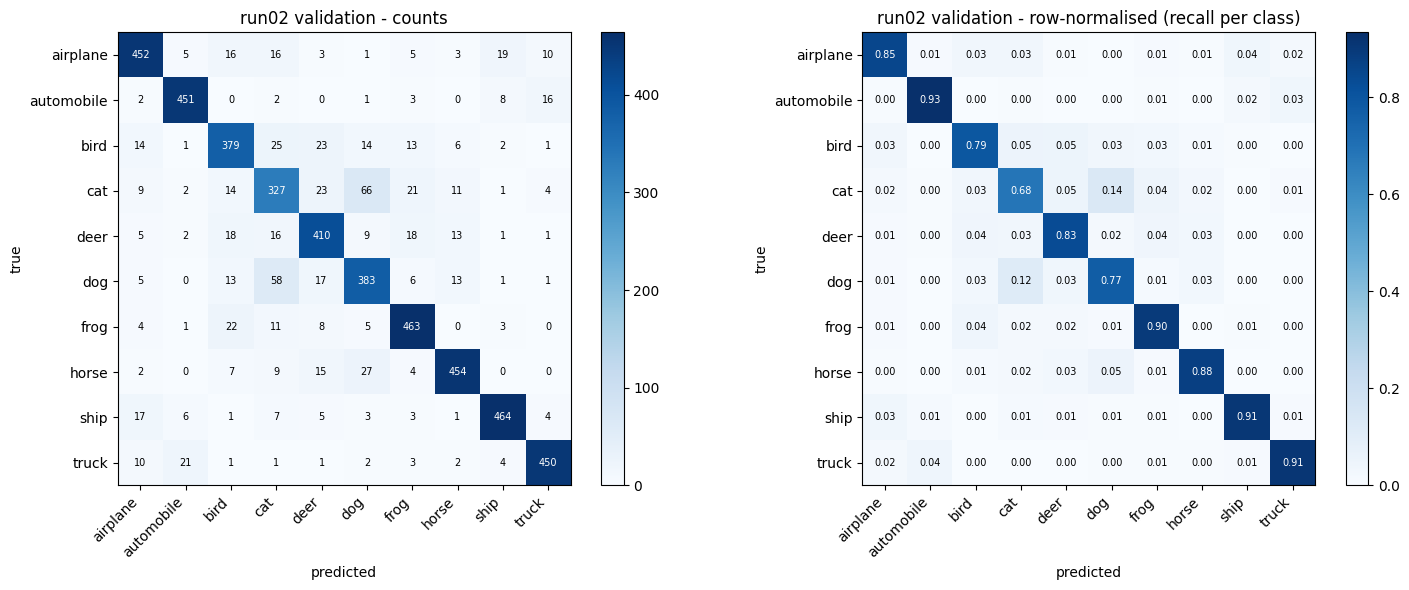

Most frequent confusions (true -> predicted):
 true predicted  count
  cat       dog     66
  dog       cat     58
horse       dog     27
 bird       cat     25
 bird      deer     23
  cat      deer     23
 frog      bird     22
  cat      frog     21

Per-class ranking by F1 (validation):
     class  precision  recall     f1  support
automobile     0.9223  0.9337 0.9280      483
     truck     0.9240  0.9091 0.9165      495
      ship     0.9225  0.9080 0.9152      511
     horse     0.9026  0.8764 0.8893      518
      frog     0.8590  0.8956 0.8769      517
  airplane     0.8692  0.8528 0.8610      530
      deer     0.8119  0.8316 0.8216      493
      bird     0.8047  0.7929 0.7987      478
       dog     0.7495  0.7706 0.7599      497
       cat     0.6928  0.6841 0.6884      478

Class 'cat' on validation: TP=327, FP=145, FN=151 -> precision=0.693, recall=0.684


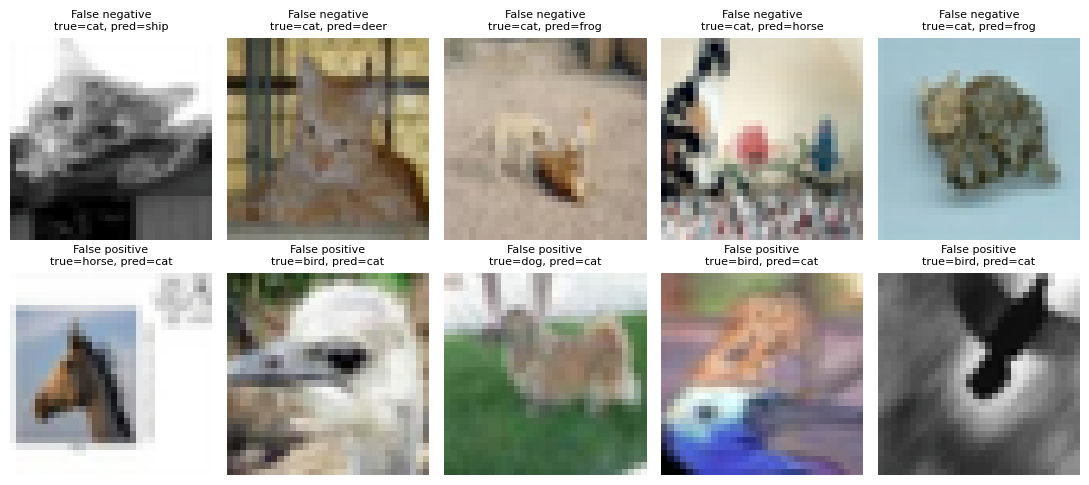


Toy example (a very conservative classifier): TP=20, FP=1, FN=80 -> precision=0.952, recall=0.200, F1=0.331
Classes of this model with the largest precision-minus-recall gap:
    class  precision  recall    gap
   horse     0.9026  0.8764 0.0262
airplane     0.8692  0.8528 0.0164
   truck     0.9240  0.9091 0.0149

Class counts in the validation split (macro vs weighted differ only because the split is not perfectly balanced): {'airplane': 530, 'automobile': 483, 'bird': 478, 'cat': 478, 'deer': 493, 'dog': 497, 'frog': 517, 'horse': 518, 'ship': 511, 'truck': 495}


In [ ]:
# metrics on the VALIDATION set for the model selected in Part 5 
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, accuracy_score

best_cfg_val = all_results[best_run_id]["signature"]["arch"]
val_model = ConfigurableCNN(best_cfg_val).to(device)
val_model.load_state_dict(torch.load(f"checkpoints/{best_run_id}.pt", map_location=device))
val_out = evaluate(val_model, val_loader)
yv, pv = val_out["targets"], val_out["preds"]
print(f"Model: {best_run_id} | validation accuracy {val_out['acc']:.4f} | validation loss {val_out['loss']:.4f}")

# Own implementation from the confusion matrix vs scikit-learn
cm_val = confusion_from_preds(yv, pv)
assert (cm_val == confusion_matrix(yv, pv)).all()
mine = metrics_from_confusion(cm_val)
for avg in ["macro", "weighted"]:
    sk = precision_recall_fscore_support(yv, pv, average=avg, zero_division=0)[:3]
    ours = (mine[f"{avg}_precision"], mine[f"{avg}_recall"], mine[f"{avg}_f1"])
    assert np.allclose(sk, ours), (avg, sk, ours)
assert np.isclose(accuracy_score(yv, pv), mine["accuracy"])
print("Own metric implementation matches scikit-learn (accuracy, macro and weighted precision/recall/F1).\n")
print(classification_report(yv, pv, target_names=CLASS_NAMES, digits=4))

def plot_confusion(cm, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    for a_, mat, t_, fmt in [(ax[0], cm, "counts", "d"), (ax[1], cm / cm.sum(1, keepdims=True), "row-normalised (recall per class)", ".2f")]:
        im = a_.imshow(mat, cmap="Blues"); a_.set_xticks(range(10)); a_.set_yticks(range(10))
        a_.set_xticklabels(CLASS_NAMES, rotation=45, ha="right"); a_.set_yticklabels(CLASS_NAMES)
        a_.set_xlabel("predicted"); a_.set_ylabel("true"); a_.set_title(f"{title} - {t_}")
        for i in range(10):
            for j in range(10):
                a_.text(j, i, format(mat[i, j], fmt), ha="center", va="center", fontsize=7, color="white" if mat[i, j] > mat.max() / 2 else "black")
        fig.colorbar(im, ax=a_, fraction=0.046)
    plt.tight_layout(); fig.savefig(fname, dpi=130, bbox_inches="tight"); plt.show()
plot_confusion(cm_val, f"{best_run_id} validation", "figures/confusion_val.png")

# Largest confusions off-diagonal
off = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm_val[i, j])) for i in range(10) for j in range(10) if i != j]
print("Most frequent confusions (true -> predicted):")
print(pd.DataFrame(sorted(off, key=lambda t: -t[2])[:8], columns=["true", "predicted", "count"]).to_string(index=False))
per_class = pd.DataFrame({"class": CLASS_NAMES, "precision": mine["precision_per_class"], "recall": mine["recall_per_class"],
                          "f1": mine["f1_per_class"], "support": mine["support"].astype(int)}).round(4)
print("\nPer-class ranking by F1 (validation):")
print(per_class.sort_values("f1", ascending=False).to_string(index=False))

# Concrete false-positive / false-negative examples for the class cat
cat = CLASS_NAMES.index("cat")
fn_idx = np.where((yv == cat) & (pv != cat))[0]; fp_idx = np.where((yv != cat) & (pv == cat))[0]
tp_cat = int(((yv == cat) & (pv == cat)).sum())
print(f"\nClass 'cat' on validation: TP={tp_cat}, FP={len(fp_idx)}, FN={len(fn_idx)} -> precision={tp_cat / max(1, tp_cat + len(fp_idx)):.3f}, recall={tp_cat / max(1, tp_cat + len(fn_idx)):.3f}")
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for row, (idxs, kind) in enumerate([(fn_idx, "False negative"), (fp_idx, "False positive")]):
    for col in range(5):
        ax = axes[row, col]; ax.axis("off")
        if col < len(idxs):
            img_, lab_ = val_dataset[int(idxs[col])]
            ax.imshow(denormalize(img_.unsqueeze(0))[0].permute(1, 2, 0)); ax.set_title(f"{kind}\ntrue={CLASS_NAMES[yv[idxs[col]]]}, pred={CLASS_NAMES[pv[idxs[col]]]}", fontsize=8)
plt.tight_layout(); fig.savefig("figures/fp_fn_cat_examples.png", dpi=130, bbox_inches="tight"); plt.show()

# Worked toy example: high precision, low recall
toy_tp, toy_fp, toy_fn = 20, 1, 80
print(f"\nToy example (a very conservative classifier): TP={toy_tp}, FP={toy_fp}, FN={toy_fn} -> "
      f"precision={toy_tp / (toy_tp + toy_fp):.3f}, recall={toy_tp / (toy_tp + toy_fn):.3f}, F1={2 * toy_tp / (2 * toy_tp + toy_fp + toy_fn):.3f}")
gap = per_class.assign(gap=per_class.precision - per_class.recall).sort_values("gap", ascending=False).head(3)
print("Classes of this model with the largest precision-minus-recall gap:\n", gap[["class", "precision", "recall", "gap"]].to_string(index=False))
print("\nClass counts in the validation split (macro vs weighted differ only because the split is not perfectly balanced):", dict(zip(CLASS_NAMES, per_class["support"].tolist())))


## Part 7 — Final model selection and test-set evaluation

Choose your best architecture using validation results. State the selection rule you used (for example, highest validation macro F1, with validation loss as a tie-breaker). Do not select a model based on test-set performance.

Set `best_config` to the configuration you selected, train it using your chosen training procedure, and evaluate the final model on the test set. For a more rigorous final result, you may combine the original training and validation data and train from scratch using the selected hyperparameters, but document that procedure clearly. For this assignment, it is acceptable to use the model trained on the training split and selected using validation results.

Selection rule: highest validation macro-F1; ties broken by lower validation loss. No test data was used so far.
Run ID  Parameters  Best epoch (val macro-F1)  Best val accuracy  Best val loss  Macro F1 (val)
    01      111274                         19             0.7630         0.6711          0.7600
    02      423082                         19             0.8466         0.4364          0.8456
    03       29477                         20             0.6272         1.0416          0.6210
    04      111050                         20             0.6898         0.8730          0.6823
    05      111274                         20             0.7802         0.6332          0.7787

Selected: run02
{
 "input_channels": 3,
 "num_classes": 10,
 "activation": "relu",
 "conv_blocks": [
  {
   "out_channels": 32,
   "kernel_size": 3,
   "stride": 1,
   "padding": 1,
   "batch_norm": true,
   "pool": 2,
   "conv_type": "standard"
  },
  {
   "out_channels": 64,
   "kernel_size": 3,
   "stride"

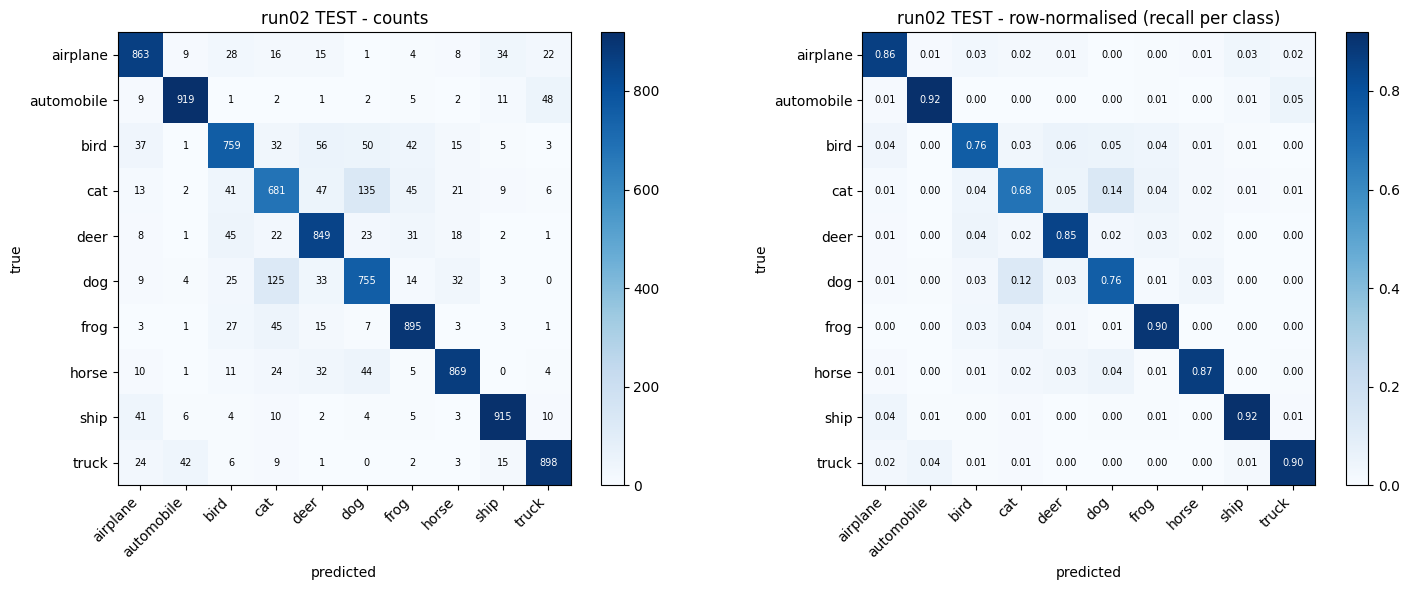

Most frequent test confusions:
       true predicted  count
       cat       dog    135
       dog       cat    125
      bird      deer     56
      bird       dog     50
automobile     truck     48
       cat      deer     47

Saved results/report_data.json


In [ ]:
# final selection and the ONE-TIME test set evaluation
print("Selection rule: highest validation macro-F1; ties broken by lower validation loss. No test data was used so far.")
print(log_df[["Run ID", "Parameters", "Best epoch (val macro-F1)", "Best val accuracy", "Best val loss", "Macro F1 (val)"]].to_string(index=False))

best_config = all_results[best_run_id]["signature"]["arch"]
print("\nSelected:", best_run_id)
print(json.dumps(best_config, indent=1))

final_model = ConfigurableCNN(best_config).to(device)
final_model.load_state_dict(torch.load(f"checkpoints/{best_run_id}.pt", map_location=device))
print("Trainable parameters:", f"{count_params(final_model):,}")
print(final_model)

test_out = evaluate(final_model, test_loader)                       # the only evaluation on the test set
yt, pt = test_out["targets"], test_out["preds"]
cm_test = confusion_from_preds(yt, pt)
mt = metrics_from_confusion(cm_test)
assert (cm_test == confusion_matrix(yt, pt)).all()
print(f"\nTEST accuracy {mt['accuracy']:.4f} | test loss {test_out['loss']:.4f}")
print(pd.DataFrame({"": ["precision", "recall", "F1"],
                    "macro": [mt["macro_precision"], mt["macro_recall"], mt["macro_f1"]],
                    "weighted": [mt["weighted_precision"], mt["weighted_recall"], mt["weighted_f1"]]}).round(4).to_string(index=False))
print()
print(classification_report(yt, pt, target_names=CLASS_NAMES, digits=4))
plot_confusion(cm_test, f"{best_run_id} TEST", "figures/confusion_test.png")

test_per_class = pd.DataFrame({"class": CLASS_NAMES, "precision": mt["precision_per_class"], "recall": mt["recall_per_class"],
                               "f1": mt["f1_per_class"], "support": mt["support"].astype(int)}).round(4)
off_t = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm_test[i, j])) for i in range(10) for j in range(10) if i != j]
print("Most frequent test confusions:\n", pd.DataFrame(sorted(off_t, key=lambda t: -t[2])[:6], columns=["true", "predicted", "count"]).to_string(index=False))

report_data = {
    "epochs": EPOCHS, "device": str(device), "seed": SEED, "batch_size": BATCH_SIZE, "mean": list(MEAN), "std": list(STD),
    "best_run_id": best_run_id, "best_config": best_config, "best_params": count_params(final_model),
    "log": log_df.to_dict(orient="records"),
    "runs": {k: {"history": v["history"], "best_epoch": v["best_epoch"], "params": v["params"], "hypothesis": hypotheses[k]} for k, v in all_results.items()},
    "val_metrics": {k: (v.tolist() if hasattr(v, "tolist") else float(v)) for k, v in mine.items()},
    "test": {"loss": test_out["loss"], **{k: (v.tolist() if hasattr(v, "tolist") else float(v)) for k, v in mt.items()}},
    "test_confusion": cm_test.tolist(), "val_confusion": cm_val.tolist(), "class_names": CLASS_NAMES,
    "test_top_confusions": sorted(off_t, key=lambda t: -t[2])[:6],
    "param_table": pd.DataFrame([(n, list(p.shape), p.numel()) for n, p in final_model.named_parameters()], columns=["tensor", "shape", "count"]).to_dict(orient="records"),
    "filter_types": filter_df["heuristic type"].str.replace(r" \(.*\)", "", regex=True).value_counts().to_dict(),
}
json.dump(report_data, open("results/report_data.json", "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("\nSaved results/report_data.json")


## Part 9 (optional) : Creative tomfoolery (+20 extra points)
In the context of CNN classification or with the concepts you have learned previously, do something interesting , fun and out of the line.


<div dir="rtl" style="text-align: right;">

# شبکه کانولوشنی چندمسیره (Multi-Path CNN)

## ۱. ایده اصلی به زبان ساده

در بخش‌های قبلی، مدل از یک مسیر متوالی تشکیل می‌شد؛ یعنی تصویر لایه‌به‌لایه از چند لایهٔ کانولوشنی عبور می‌کرد. در این بخش، به‌جای یک مسیر، از **سه مسیر کانولوشنی موازی** استفاده می‌کنم. هر مسیر تصویر را با میدان دید و هزینهٔ محاسباتی متفاوت پردازش می‌کند.

- **مسیر Fine:** بر جزئیات محلی و الگوهای ریز تمرکز دارد.
- **مسیر Wide:** با میدان دید بزرگ‌تر، اطلاعات زمینه‌ای و ساختار کلی تصویر را استخراج می‌کند.
- **مسیر Sep:** از کانولوشن‌های `Depthwise-Separable` استفاده می‌کند تا ویژگی‌ها را با هزینهٔ پارامتری کمتر بیاموزد.

در پایان، خروجی سه مسیر در امتداد بُعد کانال‌ها به یکدیگر متصل می‌شود. سپس یک لایهٔ ترکیب یا `Fusion` یاد می‌گیرد چگونه اطلاعات به‌دست‌آمده از مسیرهای مختلف را با یکدیگر ادغام کند.

**پرسش اصلی این آزمایش چنین است:**

آیا با بودجهٔ پارامتری مشابه، استفاده از چند مسیر با دیدگاه‌های متفاوت می‌تواند از عمیق‌تر یا پهن‌تر کردن یک مسیر واحد مؤثرتر باشد؟

برای پاسخ به این پرسش، همهٔ مدل‌ها صرفاً از لایه‌های `CNN` استفاده می‌کنند و هیچ مدل ازپیش‌آموزش‌دیده، `Transformer` یا ابزار خارجی به کار نمی‌رود.

---

## ۲. توضیح علمی معماری

هر مسیر از سه مرحله تشکیل شده است. در هر مرحله، عملیات کانولوشن، `BatchNorm`، تابع فعال‌سازی `ReLU` و `MaxPool2` اجرا می‌شوند.

بنابراین، خروجی هر سه مسیر از نظر ابعاد مکانی برابر با `C × 4 × 4` خواهد بود؛ اما تعداد کانال‌ها و میدان دید آن‌ها متفاوت است.

### مشخصات سه مسیر کانولوشنی

| مسیر | عملیات | تعداد کانال‌ها در سه مرحله | میدان دید در انتهای مسیر | نقش مورد انتظار |
|:---|:---|:---:|:---|:---|
| **Fine** | سه کانولوشن معمولی `3×3` | `32 → 48 → 64` | ۲۲ پیکسل | استخراج جزئیات محلی، مانند لبه‌ها، گوشه‌ها و بافت‌های ریز |
| **Wide** | یک کانولوشن `5×5` و سپس دو کانولوشن `3×3` با `dilation=2` | `24 → 48 → 64` | ۳۶ پیکسل؛ بزرگ‌تر از تصویر `32×32` | استخراج زمینه و ساختار کلی شیء |
| **Sep** | سه بلوک `Depthwise-Separable` شامل `Depthwise 3×3` و `Pointwise 1×1` | `32 → 64 → 96` | ۲۲ پیکسل | استخراج ویژگی‌ها با پارامتر کمتر و افزودن تنوع به نمایش‌ها |

### مرحلهٔ ترکیب مسیرها (Fusion)

خروجی مسیرها در امتداد کانال‌ها به یکدیگر متصل می‌شود. از آنجا که خروجی مسیرهای `Fine`، `Wide` و `Sep` به‌ترتیب دارای ۶۴، ۶۴ و ۹۶ کانال هستند، تعداد کانال‌های حاصل از الحاق برابر است با:

$$
64 + 64 + 96 = 224
$$

سپس یک کانولوشن `1×1` تعداد کانال‌ها را از ۲۲۴ به ۹۶ کاهش می‌دهد و هم‌زمان ترکیب‌های بین ویژگی‌های مسیرهای مختلف را یاد می‌گیرد.

پس از این مرحله، عملیات `Global Average Pooling` اجرا می‌شود و بردار حاصل وارد طبقه‌بند یا `Classifier` می‌شود:

`Linear(96,128) → ReLU → Dropout(0.3) → Linear(128,10)`

### دلیل علمی استفاده از مسیرهای موازی

دلیل علمی استفاده از مسیرهای موازی این است که میدان دیدهای متفاوت می‌توانند اطلاعات مکمل تولید کنند. برخی مسیرها بر دقت مکانی و جزئیات محلی تمرکز می‌کنند و برخی دیگر زمینهٔ گسترده‌تری از تصویر را در نظر می‌گیرند.

لایهٔ `Conv1×1` نیز امکان ترکیب یادگرفتنی این اطلاعات را فراهم می‌کند. از این نظر، مسیرهای مستقل را می‌توان نوعی تنوع درون‌شبکه‌ای دانست؛ بااین‌حال، این معماری معادل یک `Ensemble` مستقل نیست، زیرا مسیرها در مرحلهٔ `Fusion` با یکدیگر تعامل می‌کنند.

### محدودیت‌ها و هزینه‌های معماری

این طراحی هزینه‌هایی هم دارد. اجرای چند مسیر موازی ممکن است روی `GPU` یا `CPU`های کوچک‌تر، از نظر زمان و استفاده از منابع، به‌اندازهٔ یک مسیر متوالی کارآمد نباشد.

همچنین، اگر بودجهٔ پارامترها ثابت نگه داشته شود، هر مسیر ممکن است در مقایسه با یک مدل تک‌مسیرهٔ عمیق‌تر یا پهن‌تر، ظرفیت محدودتری داشته باشد.

---

## ۳. دیاگرام متنی معماری

```text
                         Input: 3 × 32 × 32
        ┌───────────────────────┼────────────────────────┐
        │                       │                        │
     Path FINE               Path WIDE                Path SEP
   [3×3 conv] × 3       5×5 conv; then two       [DW 3×3 + PW 1×1] × 3
   3 → 32 → 48 → 64      3×3 conv, d=2          3 → 32 → 64 → 96
                         3 → 24 → 48 → 64
        │                       │                        │
   BN + ReLU + Pool       BN + ReLU + Pool        BN + ReLU + Pool
    در هر مرحله             در هر مرحله              در هر مرحله
        │                       │                        │
   RF = 22 px              RF = 36 px               RF = 22 px
  64 × 4 × 4              64 × 4 × 4               96 × 4 × 4
        └───────────────────────┼────────────────────────┘
                                │
                  Concat در امتداد کانال‌ها
                           224 × 4 × 4
                                │
                 Conv 1×1: 224 → 96 + BN + ReLU
                              Fusion
                                │
                 Global Average Pooling → 96
                                │
       Linear(96,128) → ReLU → Dropout(0.3) → Linear(128,10)
```

---

## ۴. ترتیب اجرای سلول‌ها در Part 9

برای اجرای این بخش، سلول‌ها باید به ترتیب زیر قرار بگیرند و اجرا شوند:

| بخش | نوع سلول | توضیحات |
|:---|:---|:---|
| ۱ | `Markdown` | توضیح ایده و معماری چندمسیره |
| ۲ | کد ۱ | تعریف و بررسی مدل: پیاده‌سازی `MultiPathCNN`، تنظیم عرض مسیرها برای هم‌تراز کردن تعداد پارامترها با استفاده از `match_width`، تعریف شش مدل مقایسه، بررسی شکل خروجی‌ها و محاسبهٔ تعداد پارامترها، `MAC`ها و میدان دید |
| ۳ | کد ۲ | آموزش مدل‌ها: آموزش هر شش مدل با همان تابع `fit` و همان پروتکل آموزشی `Part 5`، سپس رسم منحنی‌های آموزش |
| ۴ | کد ۳ | جدول نتایج و مقایسه: تهیهٔ جدول مقایسهٔ دقت، تعداد پارامترها، `MAC`ها و زمان آموزش و استنتاج؛ همچنین انجام `Ablation` و رسم منحنی‌های مقایسه‌ای |
| ۵ | کد ۴ | بررسی `Feature Map`ها: مشاهدهٔ نقشه‌های ویژگی مسیرهای مختلف برای چند تصویر، محاسبهٔ آمار مربوط به ویژگی‌ها و اجرای آزمون خاموش‌کردن یک مسیر |
| ۶ | کد ۵ | انتخاب مدل نهایی: انتخاب مدل بر اساس `Validation Macro-F1` و ارزیابی مجموعهٔ `Test` فقط یک‌بار |
| ۷ | `Markdown` | تحلیل نتایج و آماده‌سازی متن گزارش و ارائه |

# وابستگی به بخش‌های قبلی نوت‌بوک

این سلول‌ها به اجزای تعریف‌شده در بخش‌های قبلی نوت‌بوک وابسته‌اند؛ از جمله:

- `fit`
- `evaluate`
- `ConfigurableCNN`
- `example_config`
- `profile`
- `plot_confusion`
- `select_best`
- `Data Loaders`

بنابراین، لازم است نوت‌بوک از ابتدا و به‌ترتیب اجرا شده باشد تا تمام توابع، کلاس‌ها، تنظیمات و بارگذارهای داده موردنیاز در دسترس باشند.
---

</div>

In [ ]:
# part 9
EPOCHS9 = EPOCHS          
print("Part 9 epoch budget per model:", EPOCHS9, "| device:", device)

def ch(c, w):
    """Scale a channel count by a width multiplier w (kept a multiple of 4, at least 8)."""
    return max(8, int(round(c * w / 4)) * 4)

def cba(cin, cout, k=3, dilation=1):
    """Conv -> BatchNorm -> ReLU with 'same' padding (also for dilated kernels)."""
    return [nn.Conv2d(cin, cout, k, padding=dilation * (k // 2), dilation=dilation, bias=False), nn.BatchNorm2d(cout), nn.ReLU()]

def sep_cba(cin, cout, k=3):
    """Depthwise-separable block: depthwise k x k (one filter per channel) + 1x1 pointwise, then BN + ReLU."""
    return [nn.Conv2d(cin, cin, k, padding=k // 2, groups=cin, bias=False), nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout), nn.ReLU()]

# Base channel counts of the three paths (before the width multiplier). Every path has 3 stages and ends at 4 x 4 resolution.
PATH_CHANNELS = {"fine": (32, 48, 64), "wide": (24, 48, 64), "sep": (32, 64, 96)}

def make_path(name, w):
    c1, c2, c3 = [ch(c, w) for c in PATH_CHANNELS[name]]
    if name == "fine":      # dense 3x3 convolutions: small receptive field, fine local detail (edges, textures)
        blocks = [cba(3, c1, 3), cba(c1, c2, 3), cba(c2, c3, 3)]
    elif name == "wide":    # 5x5 conv, then two dilated 3x3 convs (dilation 2): receptive field grows to ~ the whole 32x32 image
        blocks = [cba(3, c1, 5), cba(c1, c2, 3, dilation=2), cba(c2, c3, 3, dilation=2)]
    elif name == "sep":     # light path: depthwise-separable convolutions only
        blocks = [sep_cba(3, c1), sep_cba(c1, c2), sep_cba(c2, c3)]
    else:
        raise ValueError(name)
    return nn.ModuleList([nn.Sequential(*b, nn.MaxPool2d(2)) for b in blocks]), c3

class MultiPathCNN(nn.Module):
    """The image goes through several parallel convolutional paths; their 4x4 feature maps are concatenated,
    mixed by a 1x1 convolution (fusion), globally average-pooled and classified by the same kind of classifier head as the baseline."""
    def __init__(self, paths=("fine", "wide", "sep"), width=1.0, fuse_channels=96, hidden=128, dropout=0.3, num_classes=10):
        super().__init__()
        self.path_names = list(paths)
        self.paths = nn.ModuleDict()
        total = 0
        for p in paths:
            self.paths[p], c_out = make_path(p, width)
            total += c_out
        fc = ch(fuse_channels, width)
        self.fuse = nn.Sequential(nn.Conv2d(total, fc, 1, bias=False), nn.BatchNorm2d(fc), nn.ReLU())
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(fc, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, num_classes))

    def forward(self, x, return_stages=False, knock_out=None):
        outs, stages = [], {}
        for name, path in self.paths.items():
            h, st = x, []
            for stage in path:
                h = stage(h); st.append(h)
            stages[name] = st
            outs.append(torch.zeros_like(h) if name == knock_out else h)   # knock_out: silence one path at inference time (analysis only)
        logits = self.classifier(self.gap(self.fuse(torch.cat(outs, dim=1))))
        return (logits, stages) if return_stages else logits

def plain_cnn_cfg(w):
    """A standard (single-path) CNN of Part 4 whose filter counts are the baseline's 32-64-128 scaled by w."""
    return {**example_config, "conv_blocks": [{**b, "out_channels": ch(b["out_channels"], w)} for b in example_config["conv_blocks"]]}

def match_width(make, target, grid=np.arange(0.4, 3.001, 0.02)):
    """Pick the width multiplier whose model has the parameter count closest to `target` (fair-comparison control)."""
    return float(min(grid, key=lambda w: abs(count_params(make(float(w))) - target)))

# --- Parameter budget: the full three-path model at width 1.0 defines the target; the other models are width-matched to it ---
full_default = MultiPathCNN(("fine", "wide", "sep"), 1.0)
TARGET = count_params(full_default)
w_plain = match_width(lambda w: ConfigurableCNN(plain_cnn_cfg(w)), TARGET)
w_no_fine = match_width(lambda w: MultiPathCNN(("wide", "sep"), w), TARGET)
w_no_wide = match_width(lambda w: MultiPathCNN(("fine", "sep"), w), TARGET)
w_no_sep = match_width(lambda w: MultiPathCNN(("fine", "wide"), w), TARGET)

P9_MODELS = {   # run_id -> (display name, factory, architecture description saved in the JSON log)
    "p9_baseline":  ("Baseline CNN (Part 2)",              lambda: ConfigurableCNN(example_config), {"model": "baseline", "config": example_config}),
    "p9_plain":     ("Plain CNN, width-matched",           lambda: ConfigurableCNN(plain_cnn_cfg(w_plain)), {"model": "plain", "width": w_plain}),
    "p9_multipath": ("Multi-Path (fine+wide+sep)",         lambda: MultiPathCNN(("fine", "wide", "sep"), 1.0), {"model": "multipath", "paths": ["fine", "wide", "sep"], "width": 1.0}),
    "p9_no_fine":   ("Ablation: without fine path",        lambda: MultiPathCNN(("wide", "sep"), w_no_fine), {"model": "multipath", "paths": ["wide", "sep"], "width": w_no_fine}),
    "p9_no_wide":   ("Ablation: without wide path",        lambda: MultiPathCNN(("fine", "sep"), w_no_wide), {"model": "multipath", "paths": ["fine", "sep"], "width": w_no_wide}),
    "p9_no_sep":    ("Ablation: without separable path",   lambda: MultiPathCNN(("fine", "wide"), w_no_sep), {"model": "multipath", "paths": ["fine", "wide"], "width": w_no_sep}),
}

# --- Shape test and parameter table ---
rows = []
for rid, (name, make, arch) in P9_MODELS.items():
    m = make().to(device).eval()
    with torch.no_grad():
        out = m(torch.zeros(4, 3, 32, 32, device=device))
    assert out.shape == (4, 10)
    st = profile(m)
    rows.append({"run": rid, "model": name, "width": arch.get("width", "-"), "parameters": count_params(m), "MACs (M)": round(st["macs"] / 1e6, 2),
                 "param ratio vs full multipath": round(count_params(m) / TARGET, 3)})
print(pd.DataFrame(rows).to_string(index=False))

# --- Receptive field of the last stage of each path (theoretical, along one axis) ---
def receptive_field(layers):
    rf, jump = 1, 1
    for k, s, d in layers:
        rf += (k - 1) * d * jump; jump *= s
    return rf
rf_fine = receptive_field([(3, 1, 1), (2, 2, 1), (3, 1, 1), (2, 2, 1), (3, 1, 1), (2, 2, 1)])
rf_wide = receptive_field([(5, 1, 1), (2, 2, 1), (3, 1, 2), (2, 2, 1), (3, 1, 2), (2, 2, 1)])
rf_sep = rf_fine   # depthwise 3x3 + pointwise 1x1 has the same spatial footprint as a 3x3 convolution
print(f"\nTheoretical receptive field at the end of the path (pixels): fine={rf_fine}, wide={rf_wide}, separable={rf_sep}  (image is 32 x 32)")
del full_default


Part 9 epoch budget per model: 20 | device: cuda
         run                            model width  parameters  MACs (M)  param ratio vs full multipath
 p9_baseline            Baseline CNN (Part 2)     -      111274     10.34                          0.872
    p9_plain         Plain CNN, width-matched  1.08      128510     12.14                          1.007
p9_multipath       Multi-Path (fine+wide+sep)   1.0      127677     13.97                          1.000
  p9_no_fine      Ablation: without fine path   1.3      128441     12.52                          1.006
  p9_no_wide      Ablation: without wide path  1.28      123909     11.57                          0.970
   p9_no_sep Ablation: without separable path   1.1      130954     15.38                          1.026

Theoretical receptive field at the end of the path (pixels): fine=22, wide=36, separable=22  (image is 32 x 32)


[p9_baseline] params=111,274 | adamw lr=0.001 wd=0.0001 | epochs=20
  epoch  1/20 | train loss 1.5921 acc 0.4028 | val loss 1.5197 acc 0.4614 macroF1 0.4563 | 19s  <- best
  epoch  2/20 | train loss 1.2933 acc 0.5279 | val loss 1.3091 acc 0.5392 macroF1 0.5186 | 21s  <- best
  epoch  3/20 | train loss 1.1723 acc 0.5769 | val loss 1.1239 acc 0.5884 macroF1 0.5767 | 19s  <- best
  epoch  4/20 | train loss 1.0980 acc 0.6074 | val loss 1.1787 acc 0.5722 macroF1 0.5683 | 20s
  epoch  5/20 | train loss 1.0336 acc 0.6282 | val loss 0.9742 acc 0.6532 macroF1 0.6452 | 20s  <- best
  epoch  6/20 | train loss 0.9884 acc 0.6477 | val loss 0.9922 acc 0.6484 macroF1 0.6440 | 20s
  epoch  7/20 | train loss 0.9512 acc 0.6628 | val loss 0.9175 acc 0.6780 macroF1 0.6760 | 21s  <- best
  epoch  8/20 | train loss 0.9092 acc 0.6777 | val loss 0.9322 acc 0.6724 macroF1 0.6619 | 19s
  epoch  9/20 | train loss 0.8793 acc 0.6883 | val loss 0.8572 acc 0.6874 macroF1 0.6830 | 21s  <- best
  epoch 10/20 | train l

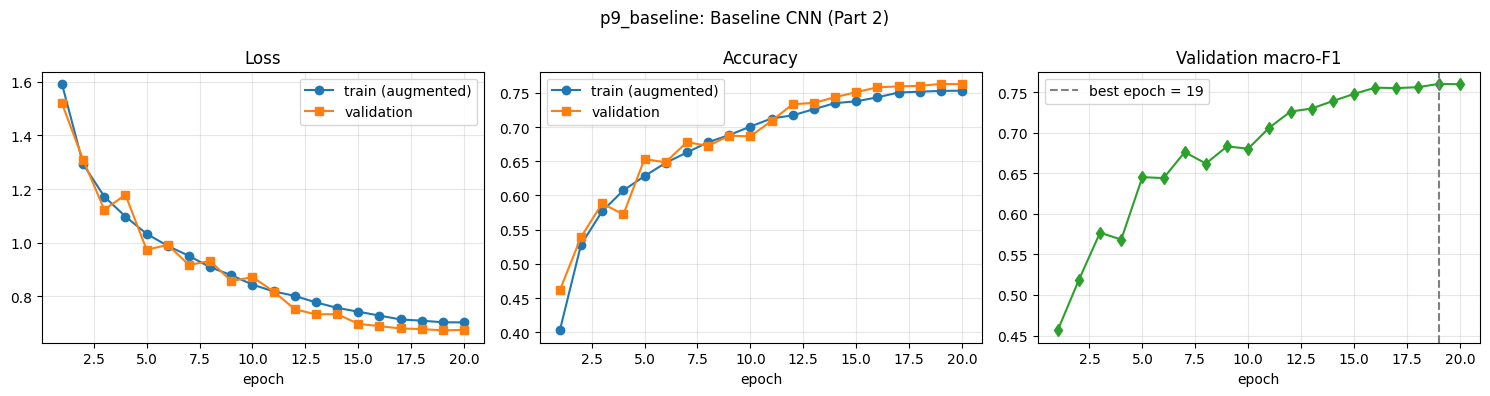

[p9_plain] params=128,510 | adamw lr=0.001 wd=0.0001 | epochs=20
  epoch  1/20 | train loss 1.5824 acc 0.4081 | val loss 1.3221 acc 0.5146 macroF1 0.5044 | 19s  <- best
  epoch  2/20 | train loss 1.2777 acc 0.5386 | val loss 1.1854 acc 0.5806 macroF1 0.5744 | 21s  <- best
  epoch  3/20 | train loss 1.1607 acc 0.5841 | val loss 1.4698 acc 0.4824 macroF1 0.4480 | 20s
  epoch  4/20 | train loss 1.0851 acc 0.6138 | val loss 1.0045 acc 0.6376 macroF1 0.6324 | 21s  <- best
  epoch  5/20 | train loss 1.0226 acc 0.6348 | val loss 0.9986 acc 0.6466 macroF1 0.6487 | 20s  <- best
  epoch  6/20 | train loss 0.9765 acc 0.6530 | val loss 0.9065 acc 0.6780 macroF1 0.6648 | 20s  <- best
  epoch  7/20 | train loss 0.9354 acc 0.6691 | val loss 0.8776 acc 0.6890 macroF1 0.6802 | 20s  <- best
  epoch  8/20 | train loss 0.8996 acc 0.6827 | val loss 0.9850 acc 0.6488 macroF1 0.6524 | 19s
  epoch  9/20 | train loss 0.8711 acc 0.6911 | val loss 0.8429 acc 0.7004 macroF1 0.6927 | 21s  <- best
  epoch 10/20 | t

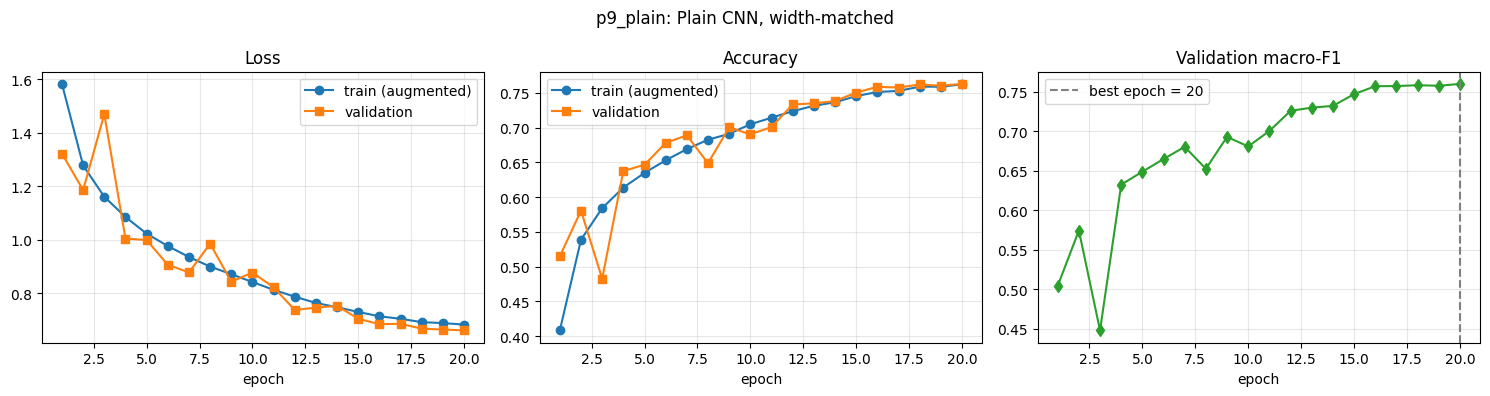

[p9_multipath] params=127,677 | adamw lr=0.001 wd=0.0001 | epochs=20
  epoch  1/20 | train loss 1.5142 acc 0.4385 | val loss 1.1957 acc 0.5704 macroF1 0.5555 | 23s  <- best
  epoch  2/20 | train loss 1.1491 acc 0.5865 | val loss 1.0800 acc 0.6084 macroF1 0.5980 | 21s  <- best
  epoch  3/20 | train loss 1.0153 acc 0.6348 | val loss 0.9835 acc 0.6534 macroF1 0.6466 | 23s  <- best
  epoch  4/20 | train loss 0.9354 acc 0.6693 | val loss 0.9171 acc 0.6692 macroF1 0.6620 | 21s  <- best
  epoch  5/20 | train loss 0.8616 acc 0.6970 | val loss 0.8723 acc 0.6992 macroF1 0.6908 | 23s  <- best
  epoch  6/20 | train loss 0.8115 acc 0.7148 | val loss 0.8144 acc 0.7158 macroF1 0.7104 | 22s  <- best
  epoch  7/20 | train loss 0.7682 acc 0.7331 | val loss 0.7956 acc 0.7274 macroF1 0.7256 | 21s  <- best
  epoch  8/20 | train loss 0.7358 acc 0.7433 | val loss 0.7421 acc 0.7462 macroF1 0.7432 | 22s  <- best
  epoch  9/20 | train loss 0.7076 acc 0.7532 | val loss 0.7383 acc 0.7454 macroF1 0.7370 | 21s
  ep

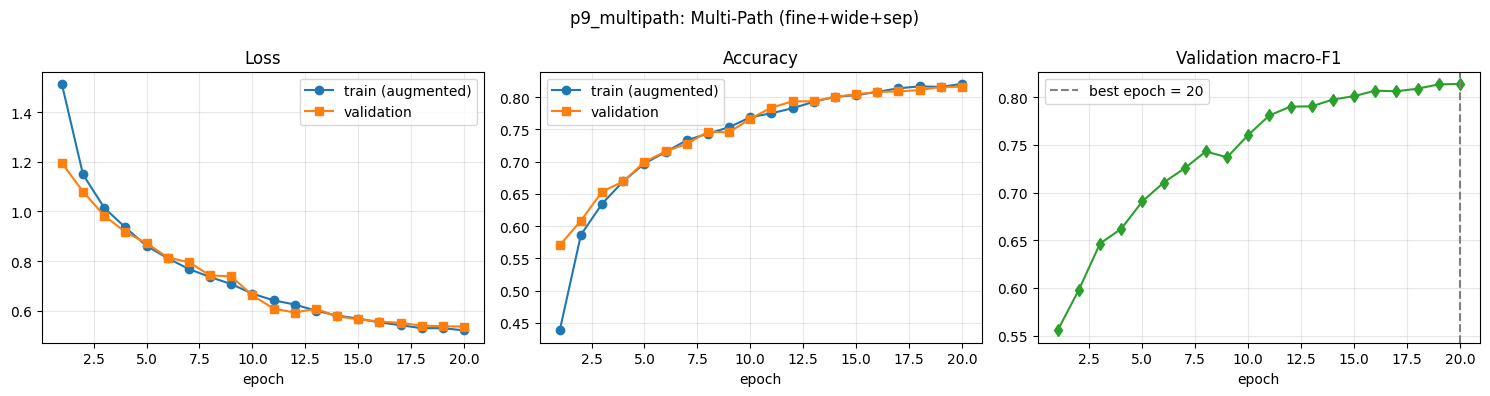

[p9_no_fine] params=128,441 | adamw lr=0.001 wd=0.0001 | epochs=20
  epoch  1/20 | train loss 1.5490 acc 0.4251 | val loss 1.3742 acc 0.5130 macroF1 0.4945 | 22s  <- best
  epoch  2/20 | train loss 1.2008 acc 0.5697 | val loss 1.0421 acc 0.6234 macroF1 0.6147 | 21s  <- best
  epoch  3/20 | train loss 1.0579 acc 0.6236 | val loss 0.9813 acc 0.6532 macroF1 0.6448 | 22s  <- best
  epoch  4/20 | train loss 0.9678 acc 0.6555 | val loss 0.9578 acc 0.6616 macroF1 0.6555 | 21s  <- best
  epoch  5/20 | train loss 0.8979 acc 0.6830 | val loss 0.9147 acc 0.6836 macroF1 0.6731 | 22s  <- best
  epoch  6/20 | train loss 0.8530 acc 0.7024 | val loss 0.9832 acc 0.6774 macroF1 0.6734 | 21s  <- best
  epoch  7/20 | train loss 0.8091 acc 0.7165 | val loss 0.7962 acc 0.7290 macroF1 0.7296 | 22s  <- best
  epoch  8/20 | train loss 0.7726 acc 0.7321 | val loss 0.7427 acc 0.7410 macroF1 0.7392 | 21s  <- best
  epoch  9/20 | train loss 0.7339 acc 0.7462 | val loss 0.7311 acc 0.7464 macroF1 0.7429 | 22s  <- be

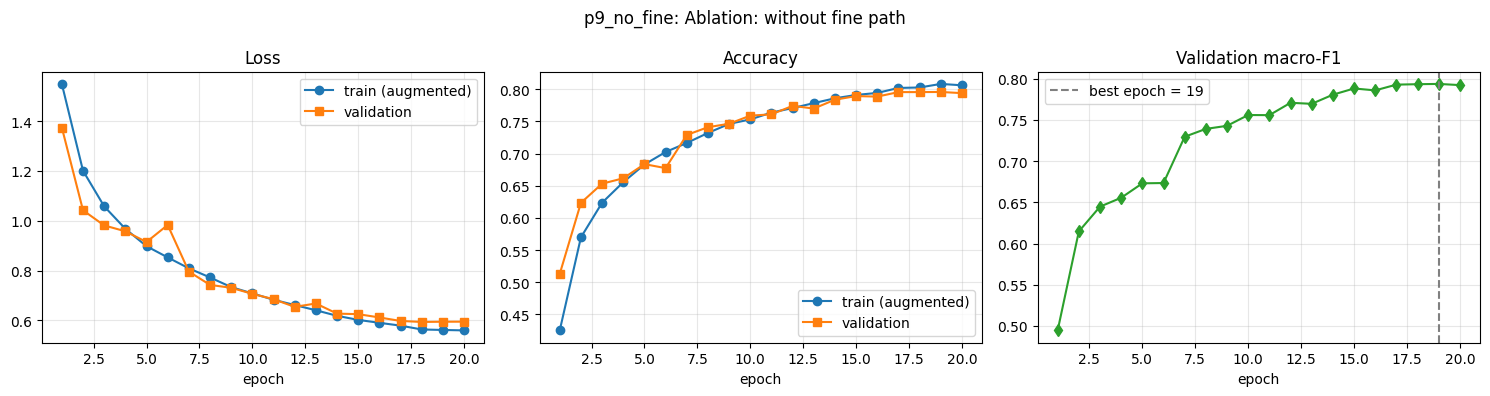

[p9_no_wide] params=123,909 | adamw lr=0.001 wd=0.0001 | epochs=20
  epoch  1/20 | train loss 1.5341 acc 0.4268 | val loss 1.4493 acc 0.4954 macroF1 0.4647 | 22s  <- best
  epoch  2/20 | train loss 1.1614 acc 0.5799 | val loss 1.2836 acc 0.5508 macroF1 0.5421 | 21s  <- best
  epoch  3/20 | train loss 1.0400 acc 0.6292 | val loss 1.0100 acc 0.6202 macroF1 0.6165 | 22s  <- best
  epoch  4/20 | train loss 0.9638 acc 0.6556 | val loss 0.9469 acc 0.6704 macroF1 0.6643 | 21s  <- best
  epoch  5/20 | train loss 0.8985 acc 0.6822 | val loss 0.8380 acc 0.7066 macroF1 0.7016 | 22s  <- best
  epoch  6/20 | train loss 0.8454 acc 0.7032 | val loss 0.9414 acc 0.6714 macroF1 0.6633 | 21s
  epoch  7/20 | train loss 0.8057 acc 0.7174 | val loss 0.8192 acc 0.7148 macroF1 0.7082 | 22s  <- best
  epoch  8/20 | train loss 0.7665 acc 0.7302 | val loss 0.7421 acc 0.7398 macroF1 0.7375 | 22s  <- best
  epoch  9/20 | train loss 0.7287 acc 0.7431 | val loss 1.0340 acc 0.6714 macroF1 0.6643 | 21s
  epoch 10/20 |

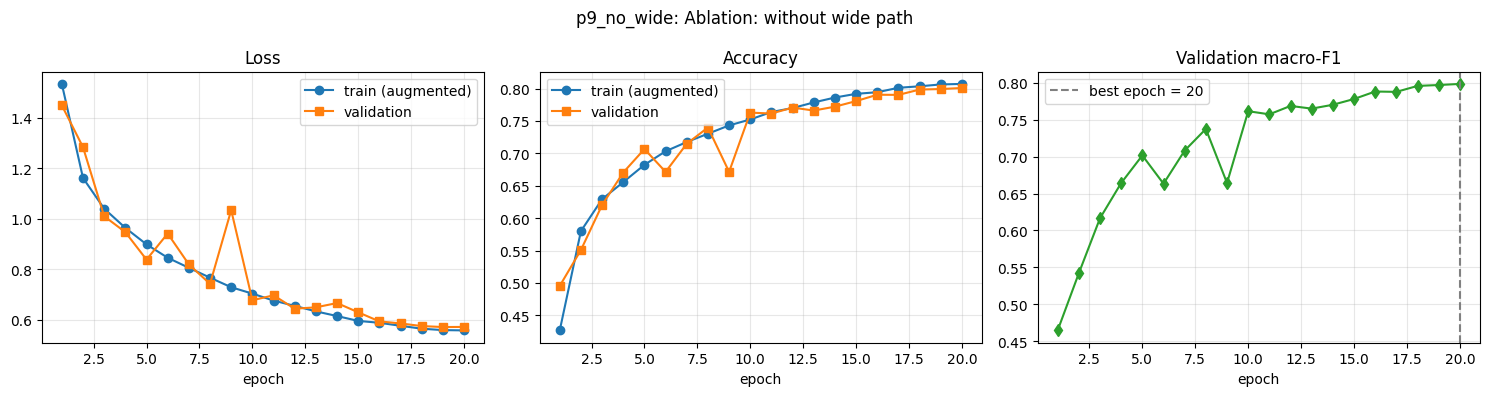

[p9_no_sep] params=130,954 | adamw lr=0.001 wd=0.0001 | epochs=20
  epoch  1/20 | train loss 1.5129 acc 0.4398 | val loss 1.2196 acc 0.5582 macroF1 0.5510 | 22s  <- best
  epoch  2/20 | train loss 1.1362 acc 0.5912 | val loss 1.0534 acc 0.6136 macroF1 0.6114 | 20s  <- best
  epoch  3/20 | train loss 1.0044 acc 0.6392 | val loss 1.0229 acc 0.6342 macroF1 0.6260 | 22s  <- best
  epoch  4/20 | train loss 0.9156 acc 0.6753 | val loss 0.8919 acc 0.6854 macroF1 0.6818 | 21s  <- best
  epoch  5/20 | train loss 0.8490 acc 0.6979 | val loss 0.8329 acc 0.7128 macroF1 0.7026 | 22s  <- best
  epoch  6/20 | train loss 0.8034 acc 0.7171 | val loss 0.8459 acc 0.7074 macroF1 0.7097 | 22s  <- best
  epoch  7/20 | train loss 0.7598 acc 0.7336 | val loss 0.7189 acc 0.7546 macroF1 0.7505 | 21s  <- best
  epoch  8/20 | train loss 0.7261 acc 0.7481 | val loss 0.7267 acc 0.7566 macroF1 0.7531 | 22s  <- best
  epoch  9/20 | train loss 0.6930 acc 0.7582 | val loss 0.7103 acc 0.7564 macroF1 0.7552 | 21s  <- bes

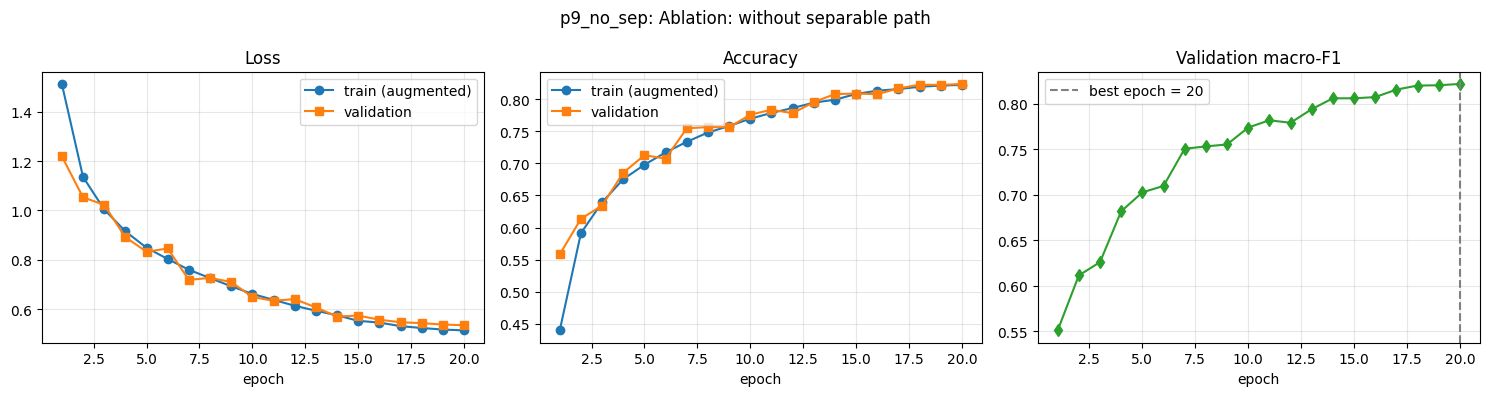

In [ ]:
# Train all Part 9 models with the SAME protocol as Part 5 (same split, seed, batch size, AdamW lr 1e-3 / wd 1e-4, cosine schedule, epochs) 
results9 = {}
for rid, (name, make, arch) in P9_MODELS.items():
    set_seed()
    model_ = make().to(device)
    res = fit(model_, rid, arch, optimizer="adamw", lr=1e-3, weight_decay=1e-4, epochs=EPOCHS9)
    res["name"] = name
    results9[rid] = res
    del model_
    plot_history(res, f"{rid}: {name}", f"figures/p9_curves_{rid}.png")


<div dir="rtl" style="text-align: right;">

## پروتکل آموزش و مقایسه شش مدل در Part 9

برای مقایسهٔ شش مدل در `Part 9`، شرایط آموزش تا حد امکان یکسان نگه داشته شد. همهٔ مدل‌ها با استفاده از یک `Split`، مقدار `Seed` یکسان (`SEED`)، اندازهٔ دسته (`Batch Size`) برابر با **۱۲۸**، بهینه‌ساز `AdamW` با نرخ یادگیری `1e-3` و مقدار `Weight Decay=1e-4`، زمان‌بندی یادگیری `Cosine` و تعداد دوره‌های آموزشی یکسان (`EPOCHS9`) آموزش دیدند.

بنابراین، مقایسهٔ نتایج این شش مدل درون `Part 9` تحت یک پروتکل آموزشی مشترک انجام شده است.

### هم‌ترازسازی تعداد پارامترها

برای نزدیک‌کردن ظرفیت مدل‌ها به یکدیگر، ضریب عرض (`Width`) تنظیم شد تا تعداد پارامترهای مدل‌ها تا حد امکان به هم نزدیک باشد.

نتایج تعداد پارامترهای مدل‌ها به شرح زیر است:

| مدل | تعداد پارامترها |
|:---|---:|
| مدل کامل (`Full Model`) | **127,677** |
| مدل سادهٔ هم‌اندازه (`Matched Simple Model`) | **128,510** |
| مدل‌های حذف مؤلفه (`Ablation Models`) | 123,909 تا 130,954 |
| مدل پایه (`Baseline`) | 111,274 |

مدل کامل دارای **127,677 پارامتر** و مدل سادهٔ هم‌اندازه دارای **128,510 پارامتر** است. همچنین، تعداد پارامترهای مدل‌های `Ablation` در بازهٔ **123,909 تا 130,954** قرار دارد.

در مقابل، مدل `Baseline` با **111,274 پارامتر**، همان مدل استفاده‌شده در `Part 2` است که عمداً بدون تغییر نگه داشته شده است. در نتیجه، این مدل حدود **۱۳٪ پارامتر کمتر** از مدل کامل دارد.

### قاعده انتخاب مدل و ارزیابی نهایی

انتخاب مدل بر اساس مقدار `Validation Macro-F1` انجام می‌شود. مجموعهٔ `Test` فقط یک‌بار و پس از انتخاب مدل، برای ارزیابی نهایی به کار می‌رود.

این شیوه باعث می‌شود مجموعهٔ `Test` در فرایند انتخاب مدل دخالت نداشته باشد و ارزیابی نهایی بر اساس داده‌هایی انجام شود که در مرحلهٔ آموزش و انتخاب مدل استفاده نشده‌اند.

</div>

,run,model,parameters,MACs (M),train time (s),inference (ms/img),best epoch,val acc,val loss,val macro-F1,final train acc,final val acc,Δ macro-F1 vs baseline
0,p9_baseline,Baseline CNN (Part 2),111274,10.34,401,0.0144,19,0.7630,0.6736,0.7600,0.7531,0.7626,0.0000
1,p9_plain,"Plain CNN, width-matched",128510,12.14,402,0.0212,20,0.7630,0.6610,0.7597,0.7624,0.7630,-0.0003
2,p9_multipath,Multi-Path (fine+wide+sep),127677,13.97,440,0.0379,20,0.8158,0.5358,0.8140,0.8203,0.8158,0.0540
3,p9_no_fine,Ablation: without fine path,128441,12.52,429,0.0320,19,0.7958,0.5949,0.7938,0.8062,0.7940,0.0338
4,p9_no_wide,Ablation: without wide path,123909,11.57,432,0.0302,20,0.8008,0.5714,0.7985,0.8071,0.8008,0.0385
5,p9_no_sep,Ablation: without separable path,130954,15.38,427,0.0309,20,0.8238,0.5351,0.8217,0.8223,0.8238,0.0617



Ablation study (validation macro-F1):
                           model  parameters  val macro-F1  Δ vs full multi-path
      Multi-Path (fine+wide+sep)      127677        0.8140                0.0000
     Ablation: without fine path      128441        0.7938               -0.0202
     Ablation: without wide path      123909        0.7985               -0.0155
Ablation: without separable path      130954        0.8217                0.0077


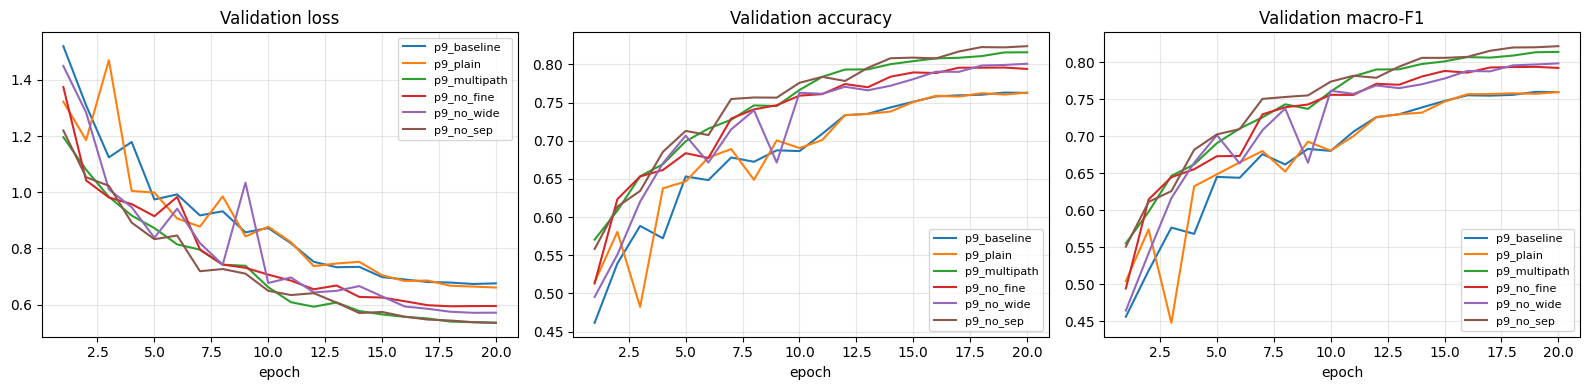

In [ ]:
# Comparison table accuracy metrics (validation), parameters, MACs, training time, inference time 
@torch.no_grad()
def inference_ms_per_image(model, reps=5):
    model.eval()
    xb, _ = next(iter(val_loader)); xb = xb.to(device)
    for _ in range(2): model(xb)                                   # warm-up
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps): model(xb)
    if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / (reps * len(xb)) * 1000

def load_best9(rid):
    m = P9_MODELS[rid][1]().to(device)
    m.load_state_dict(torch.load(f"checkpoints/{rid}.pt", map_location=device)); m.eval()
    return m

rows = []
base_f1 = results9["p9_baseline"]["best"]["val_macro_f1"]
for rid, res in results9.items():
    m = load_best9(rid)
    b, last = res["best"], res["history"][-1]
    rows.append({"run": rid, "model": res["name"], "parameters": res["params"], "MACs (M)": round(profile(m)["macs"] / 1e6, 2),
                 "train time (s)": round(res["train_time_sec"]), "inference (ms/img)": round(inference_ms_per_image(m), 4),
                 "best epoch": res["best_epoch"], "val acc": round(b["val_acc"], 4), "val loss": round(b["val_loss"], 4),
                 "val macro-F1": round(b["val_macro_f1"], 4), "final train acc": round(last["train_acc"], 4), "final val acc": round(last["val_acc"], 4),
                 "Δ macro-F1 vs baseline": round(b["val_macro_f1"] - base_f1, 4)})
    del m
table9 = pd.DataFrame(rows)
table9.to_csv("results/part9_comparison.csv", index=False)
display(table9)

#  Ablation study effect of removing one path (all models width-matched to the same parameter budget) 
full_f1 = results9["p9_multipath"]["best"]["val_macro_f1"]
abl = [{"model": results9[r]["name"], "parameters": results9[r]["params"], "val macro-F1": round(results9[r]["best"]["val_macro_f1"], 4),
        "Δ vs full multi-path": round(results9[r]["best"]["val_macro_f1"] - full_f1, 4)} for r in ["p9_multipath", "p9_no_fine", "p9_no_wide", "p9_no_sep"]]
print("\nAblation study (validation macro-F1):")
print(pd.DataFrame(abl).to_string(index=False))

# Curves validation loss / accuracy / macro-F1 of all models, and train-vs-validation accuracy gap 
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for rid, res in results9.items():
    h = pd.DataFrame(res["history"])
    ax[0].plot(h.epoch, h.val_loss, label=rid); ax[1].plot(h.epoch, h.val_acc, label=rid); ax[2].plot(h.epoch, h.val_macro_f1, label=rid)
for a_, t_ in zip(ax, ["Validation loss", "Validation accuracy", "Validation macro-F1"]):
    a_.set_title(t_); a_.set_xlabel("epoch"); a_.grid(alpha=.3); a_.legend(fontsize=8)
plt.tight_layout(); fig.savefig("figures/p9_curves_all_models.png", dpi=130, bbox_inches="tight"); plt.show()


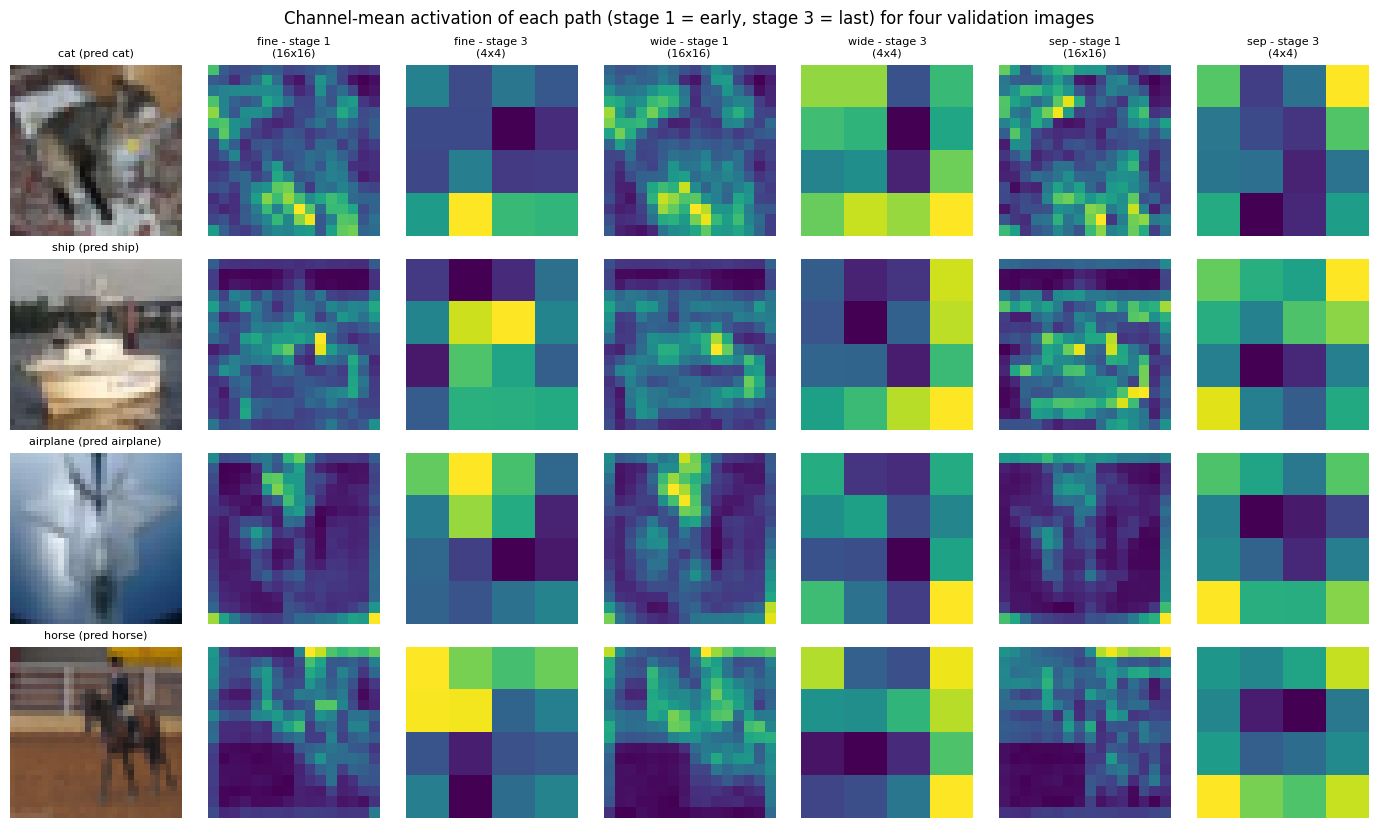

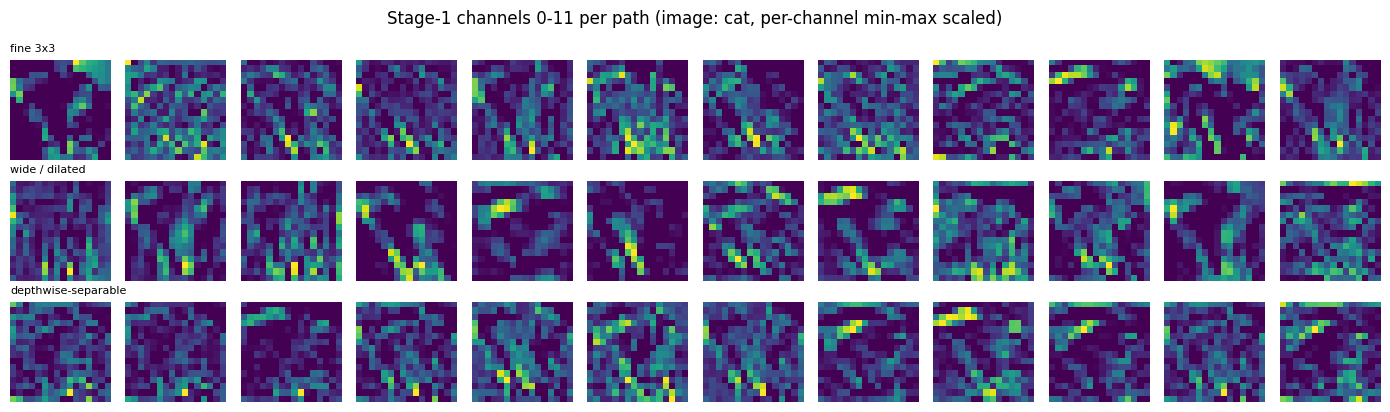

Stage-1 activation statistics per path:
path  stage-1 channels  mean activation  relative spatial gradient (detail)  fraction of zero activations
fine                32           0.4410                              1.4162                         0.352
wide                24           0.4219                              1.2626                         0.369
 sep                32           0.4577                              1.4055                         0.269

Knock-out analysis of the trained multi-path model (validation):
    silenced path  val acc  val macro-F1  Δ macro-F1
none (full model)   0.8158        0.8140      0.0000
             fine   0.3040        0.2288     -0.5852
             wide   0.6136        0.6058     -0.2082
              sep   0.7420        0.7319     -0.0821


In [ ]:
#   Feature maps of the three paths for several images + knock-out and frequency analysis 
mp = load_best9("p9_multipath")
val_labels9 = np.array(val_dataset.dataset.targets)[val_dataset.indices]
show_classes = ["cat", "ship", "airplane", "horse"]
show_idx = [int(np.where(val_labels9 == CLASS_NAMES.index(c))[0][0]) for c in show_classes]
PATH_COLORS = {"fine": "fine 3x3", "wide": "wide / dilated", "sep": "depthwise-separable"}

def stages_of(idx):
    img, lab = val_dataset[idx]
    with torch.no_grad():
        logits, st = mp(img.unsqueeze(0).to(device), return_stages=True)
    return img, lab, CLASS_NAMES[logits.argmax(1).item()], {k: [s[0].cpu() for s in v] for k, v in st.items()}

# Channel-mean activation map of stage 1 (16x16) and stage 3 (4x4) of every path, for 4 images of different classes
fig, axes = plt.subplots(len(show_idx), 1 + 6, figsize=(14, 2.1 * len(show_idx)))
for r, idx in enumerate(show_idx):
    img, lab, pred, st = stages_of(idx)
    axes[r, 0].imshow(denormalize(img.unsqueeze(0))[0].permute(1, 2, 0)); axes[r, 0].set_title(f"{CLASS_NAMES[lab]} (pred {pred})", fontsize=8); axes[r, 0].axis("off")
    c = 1
    for p in ["fine", "wide", "sep"]:
        for s in (0, 2):
            axes[r, c].imshow(st[p][s].mean(0).numpy(), cmap="viridis"); axes[r, c].axis("off")
            if r == 0: axes[r, c].set_title(f"{p} - stage {s + 1}\n({st[p][s].shape[1]}x{st[p][s].shape[2]})", fontsize=8)
            c += 1
fig.suptitle("Channel-mean activation of each path (stage 1 = early, stage 3 = last) for four validation images"); plt.tight_layout()
fig.savefig("figures/p9_path_mean_maps.png", dpi=130, bbox_inches="tight"); plt.show()

#  Individual channels (first 12) of stage 1 of every path for the first image
img, lab, pred, st = stages_of(show_idx[0])
fig, axes = plt.subplots(3, 12, figsize=(14, 4.2))
for r, p in enumerate(["fine", "wide", "sep"]):
    for k in range(12):
        a = st[p][0][k].numpy(); axes[r, k].imshow((a - a.min()) / (a.max() - a.min() + 1e-8), cmap="viridis"); axes[r, k].axis("off")
    axes[r, 0].set_title(PATH_COLORS[p], fontsize=8, loc="left")
fig.suptitle(f"Stage-1 channels 0-11 per path (image: {CLASS_NAMES[lab]}, per-channel min-max scaled)"); plt.tight_layout()
fig.savefig("figures/p9_path_channels.png", dpi=130, bbox_inches="tight"); plt.show()

# Spatial-detail statistic: mean absolute spatial gradient of stage-1 maps relative to their mean activation (higher = finer detail)
xb, _ = next(iter(val_loader)); xb = xb.to(device)
with torch.no_grad():
    _, st_b = mp(xb, return_stages=True)
detail_rows = []
for p in ["fine", "wide", "sep"]:
    a = st_b[p][0]                                                   # (B, C, 16, 16)
    grad = (a[:, :, :, 1:] - a[:, :, :, :-1]).abs().mean() + (a[:, :, 1:, :] - a[:, :, :-1, :]).abs().mean()
    detail_rows.append({"path": p, "stage-1 channels": a.shape[1], "mean activation": round(a.mean().item(), 4),
                        "relative spatial gradient (detail)": round((grad / (a.mean() + 1e-8)).item(), 4),
                        "fraction of zero activations": round((a == 0).float().mean().item(), 3)})
print("Stage-1 activation statistics per path:"); print(pd.DataFrame(detail_rows).to_string(index=False))

# Knock-out test: silence one path at inference (the network was trained with all three) and measure validation performance
ko_rows = []
for ko in [None, "fine", "wide", "sep"]:
    preds, targets = [], []
    with torch.no_grad():
        for xb_, yb_ in val_loader:
            preds.append(mp(xb_.to(device), knock_out=ko).argmax(1).cpu()); targets.append(yb_)
    preds, targets = torch.cat(preds).numpy(), torch.cat(targets).numpy()
    mm = metrics_from_confusion(confusion_from_preds(targets, preds))
    ko_rows.append({"silenced path": ko or "none (full model)", "val acc": round(mm["accuracy"], 4), "val macro-F1": round(mm["macro_f1"], 4)})
ko_df = pd.DataFrame(ko_rows); ko_df["Δ macro-F1"] = (ko_df["val macro-F1"] - ko_df["val macro-F1"].iloc[0]).round(4)
print("\nKnock-out analysis of the trained multi-path model (validation):"); print(ko_df.to_string(index=False))


Selection rule: highest validation macro-F1 (tie-break: validation loss). Selected: p9_no_sep - Ablation: without separable path
         run  parameters  val acc  val loss  val macro-F1
 p9_baseline      111274   0.7630    0.6736        0.7600
    p9_plain      128510   0.7630    0.6610        0.7597
p9_multipath      127677   0.8158    0.5358        0.8140
  p9_no_fine      128441   0.7958    0.5949        0.7938
  p9_no_wide      123909   0.8008    0.5714        0.7985
   p9_no_sep      130954   0.8238    0.5351        0.8217

TEST accuracy 0.8063 | test loss 0.5603 | parameters 130,954
           macro  weighted
precision 0.8049    0.8049
   recall 0.8063    0.8063
       F1 0.8053    0.8053

              precision    recall  f1-score   support

    airplane     0.8099    0.8350    0.8223      1000
  automobile     0.9095    0.9150    0.9123      1000
        bird     0.7387    0.7180    0.7282      1000
         cat     0.6517    0.5970    0.6232      1000
        deer     0.7686

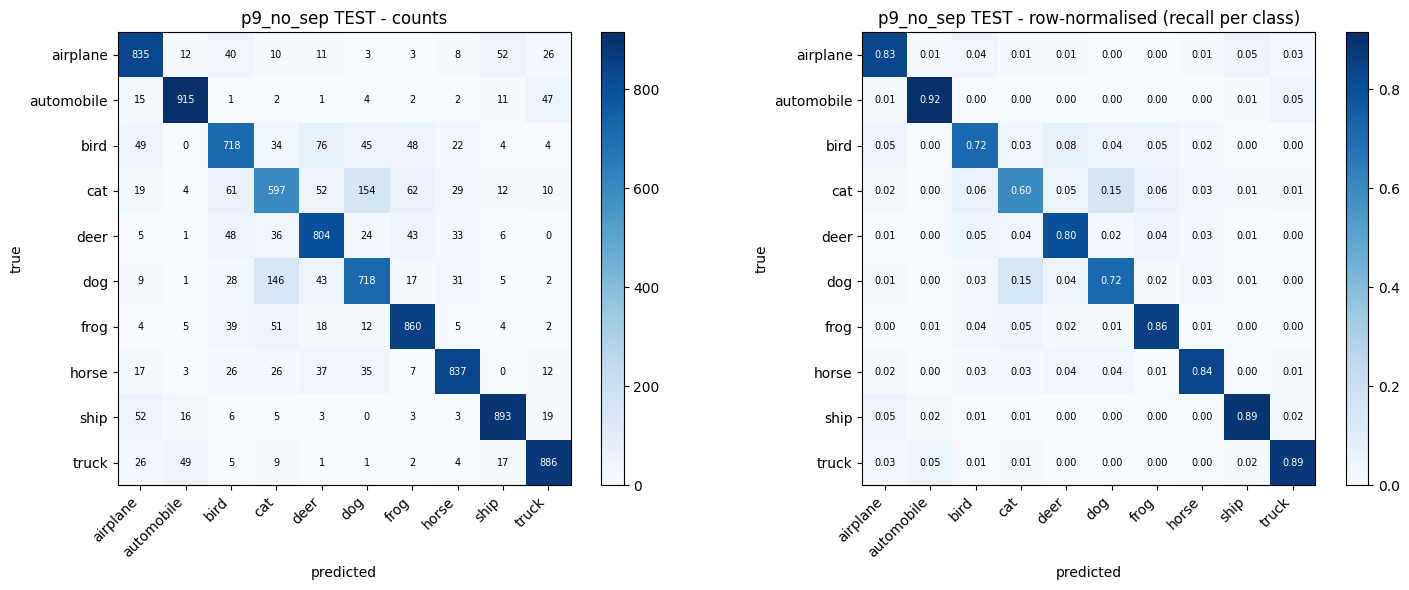

Most frequent test confusions:
    true predicted  count
     cat       dog    154
     dog       cat    146
    bird      deer     76
     cat      frog     62
     cat      bird     61
airplane      ship     52

Saved results/part9_summary.json


In [ ]:
# Final choice among the Part 9 models: highest VALIDATION macro-F1 then ONE test evaluation 
best9 = select_best(results9)
print("Selection rule: highest validation macro-F1 (tie-break: validation loss). Selected:", best9, "-", results9[best9]["name"])
print(table9[["run", "parameters", "val acc", "val loss", "val macro-F1"]].to_string(index=False))

final9 = load_best9(best9)
test9 = evaluate(final9, test_loader)                                  # <- the only Part 9 evaluation on the test set
cm9 = confusion_from_preds(test9["targets"], test9["preds"])
m9 = metrics_from_confusion(cm9)
assert (cm9 == confusion_matrix(test9["targets"], test9["preds"])).all()
print(f"\nTEST accuracy {m9['accuracy']:.4f} | test loss {test9['loss']:.4f} | parameters {count_params(final9):,}")
print(pd.DataFrame({"": ["precision", "recall", "F1"], "macro": [m9["macro_precision"], m9["macro_recall"], m9["macro_f1"]],
                    "weighted": [m9["weighted_precision"], m9["weighted_recall"], m9["weighted_f1"]]}).round(4).to_string(index=False))
print(); print(classification_report(test9["targets"], test9["preds"], target_names=CLASS_NAMES, digits=4))
plot_confusion(cm9, f"{best9} TEST", "figures/p9_confusion_test.png")
off9 = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm9[i, j])) for i in range(10) for j in range(10) if i != j]
print("Most frequent test confusions:"); print(pd.DataFrame(sorted(off9, key=lambda t: -t[2])[:6], columns=["true", "predicted", "count"]).to_string(index=False))

json.dump({"epochs": EPOCHS9, "seed": SEED, "selected": best9, "table": table9.to_dict(orient="records"), "ablation": abl, "knock_out": ko_df.to_dict(orient="records"),
           "detail": detail_rows, "receptive_field": {"fine": rf_fine, "wide": rf_wide, "sep": rf_sep},
           "test": {"loss": test9["loss"], **{k: (v.tolist() if hasattr(v, "tolist") else float(v)) for k, v in m9.items()}}, "test_confusion": cm9.tolist()},
          open("results/part9_summary.json", "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("\nSaved results/part9_summary.json")
